In [1]:
# ============================================================
# CELL 1 (05_xgboost_model): First XGBoost models on the headline test
# What it does:
#   1) setup from disk: imports, src/metrics.py and src/splits.py, rulebook,
#      station_meta, model_base.parquet (same row filter as notebook 04:
#      valid target, CHIRPS blend and ERA5-Land rain blend present)
#   2) feature set "primary": 2 calendar + 9 CHIRPS + 5 ERA5-Land rain + 10 ERA5-Land
#      atmospheric anomaly/tendency features (no lat/lon/elevation, no station id,
#      no gauge-neighbour data)
#   3) two models per fold:
#        tweedie : objective reg:tweedie (power 1.5) on gauge rain (mm)
#        resid   : squared error on (gauge - CHIRPS blend); prediction =
#                  max(0, CHIRPS blend + model output)
#   4) validation: fit on the training stations 1983-2005, early stopping on the
#      same stations 2006-2010, then refit on 1983-2010 with 1.15 x the best number
#      of trees and predict the headline rows (held-out station, 2011-2023);
#      the held-out station is never used in training
#   5) both fold schemes: blocked (30 km) and plain LOSO
#   6) saves outputs/preds_primary.parquet and outputs/xgb_scores_primary.csv
#   7) prints a summary with the baselines for reference, per-station KGE,
#      per-station percent bias and the mean number of trees
# Expected run time: a few minutes (progress is printed per fold)
# ============================================================
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"
OUTPUT_DIR = ROOT / "outputs"
sys.path.insert(0, str(ROOT / "src"))
import metrics, splits

with open(PROCESSED_DIR / "eda_decisions.json") as f:
    dec = json.load(f)
TRAIN_END = dec["temporal_split"]["train"][1]
THR = dec["extreme_thresholds_mm"]
meta = pd.read_csv(PROCESSED_DIR / "station_meta.csv", index_col="station")
stations = list(meta.index)
dist = splits.distance_matrix(meta)
folds_by_scheme = {
    "blocked": splits.make_folds(stations, dist, "blocked", dec["spatial_split"]["block_km"]),
    "loso": splits.make_folds(stations, dist, "loso"),
}

base = pd.read_parquet(PROCESSED_DIR / "model_base.parquet")
valid = (base.dropna(subset=["rain", "chirps_blend_c", "era_p_blend"])
             .sort_values(["station", "date"]).reset_index(drop=True))

# --- 2) features ---
CAL = ["doy_sin", "doy_cos"]
CHIRPS_F = ["chirps_c_dm1", "chirps_c_d0", "chirps_c_dp1", "chirps_blend_c",
            "chirps_blend_mean9", "chirps_blend_max9", "chirps_blend_std9",
            "chirps_blend_mean9_prev", "chirps_blend_mean9_sum3"]
ERA_P = ["era_p_blend", "era_p_dm1", "era_p_d0", "era_p_blend_prev", "era_p_blend_sum3"]
ERA_ATM = ["anom_era_t2m_c", "anom_era_dtr_c", "anom_era_dewdep_c", "anom_era_rh_pct",
           "anom_era_u10", "anom_era_v10", "anom_era_wspd", "anom_era_sp_hpa",
           "anom_era_soil_w1", "era_dsp_hpa"]
FEATS = CAL + CHIRPS_F + ERA_P + ERA_ATM
missing_cols = [c for c in FEATS if c not in valid.columns]
assert not missing_cols, f"missing columns: {missing_cols}"
print(f"Rows: {len(valid)} | features: {len(FEATS)}")

X = valid[FEATS].to_numpy(dtype=float)
obs = valid["rain"].to_numpy()
chirps = valid["chirps_blend_c"].to_numpy()
dates = valid["date"].to_numpy()
early_fit = (valid["date"] <= pd.Timestamp("2005-12-31")).to_numpy()
val_block = ((valid["date"] >= pd.Timestamp("2006-01-01"))
             & (valid["date"] <= pd.Timestamp("2010-12-31"))).to_numpy()

PARAMS = dict(learning_rate=0.05, max_depth=4, min_child_weight=30, subsample=0.8,
              colsample_bytree=0.8, reg_lambda=5.0, tree_method="hist",
              n_jobs=-1, random_state=0)

def make_model(kind, n_estimators, early=None):
    if kind == "tweedie":
        obj = dict(objective="reg:tweedie", tweedie_variance_power=1.5)
    else:
        obj = dict(objective="reg:squarederror")
    return xgb.XGBRegressor(n_estimators=n_estimators, early_stopping_rounds=early,
                            **obj, **PARAMS)

def target(kind):
    return obs if kind == "tweedie" else obs - chirps

# --- 3-5) training and scoring ---
rows, preds = [], []
t0 = time.time()
for scheme, folds in folds_by_scheme.items():
    for fo in folds:
        h = fo["held_out"]
        m = splits.fold_masks(valid, fo, TRAIN_END)
        i_fit, i_val = m["train"] & early_fit, m["train"] & val_block
        i_all, i_te = m["train"], m["headline"]
        for kind in ("tweedie", "resid"):
            y = target(kind)
            mdl = make_model(kind, 1500, early=50)
            mdl.fit(X[i_fit], y[i_fit], eval_set=[(X[i_val], y[i_val])], verbose=False)
            best = int(mdl.best_iteration) + 1
            fin = make_model(kind, max(50, int(best * 1.15)))
            fin.fit(X[i_all], y[i_all], verbose=False)
            out = fin.predict(X[i_te])
            sim = out if kind == "tweedie" else np.clip(chirps[i_te] + out, 0, None)
            sc = metrics.score_all(dates[i_te], obs[i_te], sim, THR[h])
            sc["alpha"] = float(np.std(sim) / np.std(obs[i_te]))
            rows.append({"label": f"XGB {kind}/{scheme[:4]}", "scheme": scheme, "model": kind,
                         "station": h, "best_iter": best, **sc})
            preds.append(pd.DataFrame({"scheme": scheme, "model": kind, "station": h,
                                       "date": dates[i_te], "obs": obs[i_te], "sim": sim}))
        print(f"{scheme:8s} {h:16s} done | elapsed {time.time() - t0:.0f}s")

res = pd.DataFrame(rows)
res.to_csv(OUTPUT_DIR / "xgb_scores_primary.csv", index=False)
pd.concat(preds, ignore_index=True).to_parquet(OUTPUT_DIR / "preds_primary.parquet")

# --- 7) summaries, with baselines for reference ---
bl = pd.read_csv(OUTPUT_DIR / "baseline_scores.csv")
short = {"raw CHIRPS": "rawCHIRPS", "raw ERA5-Land": "rawERA5L", "raw mean(CHIRPS,ERA5L)": "rawMean",
         "QM local CHIRPS (oracle)": "QMlocal*", "QM transfer CHIRPS": "QMt-CHIRPS",
         "QM transfer mean(CHIRPS,ERA5L)": "QMt-mean", "IDW gauges (1/d^2)": "IDW"}
bl["label"] = [short[b] if s == "none" else f"{short[b]}/{s[:4]}"
               for b, s in zip(bl["baseline"], bl["scheme"])]
bl["alpha"] = np.nan
allres = pd.concat([bl, res], ignore_index=True)
allres["abs_pbias"] = allres["pbias"].abs()

DRY = ["Kunchha", "Bandipur", "Damauli"]
order = ["rawCHIRPS", "QMlocal*", "QMt-CHIRPS/bloc", "QMt-mean/bloc", "IDW/bloc",
         "XGB tweedie/bloc", "XGB resid/bloc",
         "QMt-CHIRPS/loso", "QMt-mean/loso", "IDW/loso", "XGB tweedie/loso", "XGB resid/loso"]
g = allres.groupby("label")
summ = g[["kge", "r", "alpha", "abs_pbias", "wet_far", "q95_ratio", "rx1_ratio", "p95_pod"]].mean()
summ["kge_dry3"] = allres[allres["station"].isin(DRY)].groupby("label")["kge"].mean()
summ["kge_wet4"] = allres[~allres["station"].isin(DRY)].groupby("label")["kge"].mean()
summ = summ.loc[order, ["kge", "kge_dry3", "kge_wet4", "r", "alpha", "abs_pbias", "wet_far",
                        "q95_ratio", "rx1_ratio", "p95_pod"]].round(2)
print("\nHeadline test (held-out station, 2011-2023): means over 7 stations (alpha = std(sim)/std(obs))")
print(summ.to_string())

cols = ["rawCHIRPS", "QMt-mean/bloc", "XGB tweedie/bloc", "XGB resid/bloc",
        "QMt-mean/loso", "XGB tweedie/loso", "XGB resid/loso"]
print("\nPer-station KGE:")
print(allres.pivot_table(index="station", columns="label", values="kge")
      .loc[stations, cols].round(2).to_string())
xl = [c for c in cols if c.startswith("XGB")]
print("\nPer-station percent bias (XGB models):")
print(allres.pivot_table(index="station", columns="label", values="pbias")
      .loc[stations, xl].round(0).to_string())
print("\nMean number of trees:", res.groupby("label")["best_iter"].mean().round(0).to_dict())
print("\nSaved: outputs/preds_primary.parquet, outputs/xgb_scores_primary.csv")

Rows: 101628 | features: 26
blocked  Pokhara Airport  done | elapsed 3s
blocked  Kunchha          done | elapsed 5s
blocked  Bandipur         done | elapsed 6s
blocked  Lumle            done | elapsed 7s
blocked  Damauli          done | elapsed 8s
blocked  Sikles           done | elapsed 9s
blocked  Lamachaur        done | elapsed 10s
loso     Pokhara Airport  done | elapsed 12s
loso     Kunchha          done | elapsed 14s
loso     Bandipur         done | elapsed 15s
loso     Lumle            done | elapsed 17s
loso     Damauli          done | elapsed 19s
loso     Sikles           done | elapsed 21s
loso     Lamachaur        done | elapsed 23s

Headline test (held-out station, 2011-2023): means over 7 stations (alpha = std(sim)/std(obs))
                   kge  kge_dry3  kge_wet4     r  alpha  abs_pbias  wet_far  q95_ratio  rx1_ratio  p95_pod
label                                                                                                     
rawCHIRPS         0.41      0.37      

In [2]:
# ============================================================
# CELL 2 (05_xgboost_model): Bias diagnosis + climatology-normalised model
# What it does:
#   1) setup from disk (same row filter and feature list as Cell 1)
#   2) diagnostic: for each fold, the mean annual gauge rainfall (1983-2010) of the
#      training stations vs the held-out station, next to the percent bias of
#      raw CHIRPS and of the two models from Cell 1 (tweedie, resid)
#   3) satellite climatology per location (mean daily CHIRPS blend and ERA5-Land
#      rain blend, 1983-2010, all days, no gauge data); prints it in mm/yr,
#      Chapakot included
#   4) model "rel": CHIRPS features divided by the location's CHIRPS mean, ERA5-Land
#      rain features by its ERA5-Land mean, target = gauge / CHIRPS mean, tweedie
#      objective, same validation scheme as Cell 1 (fit 1983-2005, early stop
#      2006-2010, refit 1983-2010, predict headline rows); prediction multiplied
#      back by the CHIRPS mean. Both fold schemes
#   5) saves outputs/preds_rel.parquet and outputs/xgb_scores_rel.csv
#   6) prints the summary (rawCHIRPS, QMlocal*, XGB tweedie, resid, rel; blocked and
#      loso), then per-station KGE and percent bias for tweedie vs rel
# ============================================================
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"
SAT_DIR = ROOT / "data" / "satellite"
OUTPUT_DIR = ROOT / "outputs"
sys.path.insert(0, str(ROOT / "src"))
import metrics, splits

with open(PROCESSED_DIR / "eda_decisions.json") as f:
    dec = json.load(f)
TRAIN_END = dec["temporal_split"]["train"][1]
THR = dec["extreme_thresholds_mm"]
meta = pd.read_csv(PROCESSED_DIR / "station_meta.csv", index_col="station")
stations = list(meta.index)
dist = splits.distance_matrix(meta)
folds_by_scheme = {
    "blocked": splits.make_folds(stations, dist, "blocked", dec["spatial_split"]["block_km"]),
    "loso": splits.make_folds(stations, dist, "loso"),
}

base = pd.read_parquet(PROCESSED_DIR / "model_base.parquet")
valid = (base.dropna(subset=["rain", "chirps_blend_c", "era_p_blend"])
             .sort_values(["station", "date"]).reset_index(drop=True))

CAL = ["doy_sin", "doy_cos"]
CHIRPS_F = ["chirps_c_dm1", "chirps_c_d0", "chirps_c_dp1", "chirps_blend_c",
            "chirps_blend_mean9", "chirps_blend_max9", "chirps_blend_std9",
            "chirps_blend_mean9_prev", "chirps_blend_mean9_sum3"]
ERA_P = ["era_p_blend", "era_p_dm1", "era_p_d0", "era_p_blend_prev", "era_p_blend_sum3"]
ERA_ATM = ["anom_era_t2m_c", "anom_era_dtr_c", "anom_era_dewdep_c", "anom_era_rh_pct",
           "anom_era_u10", "anom_era_v10", "anom_era_wspd", "anom_era_sp_hpa",
           "anom_era_soil_w1", "era_dsp_hpa"]
FEATS = CAL + CHIRPS_F + ERA_P + ERA_ATM
assert not [c for c in FEATS if c not in valid.columns]

obs = valid["rain"].to_numpy()
dates = valid["date"].to_numpy()
early_fit = (valid["date"] <= pd.Timestamp("2005-12-31")).to_numpy()
val_block = ((valid["date"] >= pd.Timestamp("2006-01-01"))
             & (valid["date"] <= pd.Timestamp("2010-12-31"))).to_numpy()

# --- 2) diagnostic ---
rain_final = pd.read_parquet(PROCESSED_DIR / "rain_final.parquet")[stations]
ann_gauge = rain_final.loc[:TRAIN_END].mean() * 365.25
res_prev = pd.read_csv(OUTPUT_DIR / "xgb_scores_primary.csv")
bl = pd.read_csv(OUTPUT_DIR / "baseline_scores.csv")
chirps_pb = bl[bl["baseline"] == "raw CHIRPS"].set_index("station")["pbias"]

rows = []
for scheme, folds in folds_by_scheme.items():
    for fo in folds:
        h = fo["held_out"]
        tm = ann_gauge[fo["train"]].mean()
        def pb(model):
            s = res_prev[(res_prev["scheme"] == scheme) & (res_prev["model"] == model)
                         & (res_prev["station"] == h)]
            return round(float(s["pbias"].iloc[0]), 0)
        rows.append({"scheme": scheme, "held_out": h,
                     "held_mm_yr": round(ann_gauge[h]), "train_mean_mm_yr": round(tm),
                     "train_vs_held_%": round(100 * (tm / ann_gauge[h] - 1)),
                     "bias_rawCHIRPS_%": round(float(chirps_pb[h]), 0),
                     "bias_tweedie_%": pb("tweedie"), "bias_resid_%": pb("resid")})
print("2) Training-station mean rainfall vs held-out station, and the models' bias (headline test)")
print(pd.DataFrame(rows).to_string(index=False))

# --- 3) satellite climatology per location ---
sat = pd.read_parquet(SAT_DIR / "satellite_features_model.parquet")
s_tr = sat[sat["date"] <= TRAIN_END]
scale = s_tr.groupby("station")[["chirps_blend_c", "era_p_blend"]].mean()
scale.columns = ["c_mean", "e_mean"]
print("\n3) Satellite climatology, 1983-2010 (mm/yr), gauge for comparison:")
clim = pd.DataFrame({"CHIRPS_mm_yr": (scale["c_mean"] * 365.25).round(0),
                     "ERA5L_mm_yr": (scale["e_mean"] * 365.25).round(0),
                     "gauge_mm_yr": ann_gauge.round(0)})
print(clim.to_string())

# --- 4) normalised model ---
cm = valid["station"].map(scale["c_mean"]).to_numpy()
em = valid["station"].map(scale["e_mean"]).to_numpy()
Xn = valid[FEATS].to_numpy(dtype=float).copy()
for c in CHIRPS_F:
    Xn[:, FEATS.index(c)] /= cm
for c in ERA_P:
    Xn[:, FEATS.index(c)] /= em
yrel = obs / cm

PARAMS = dict(learning_rate=0.05, max_depth=4, min_child_weight=30, subsample=0.8,
              colsample_bytree=0.8, reg_lambda=5.0, tree_method="hist",
              n_jobs=-1, random_state=0,
              objective="reg:tweedie", tweedie_variance_power=1.5)

rows, preds = [], []
t0 = time.time()
for scheme, folds in folds_by_scheme.items():
    for fo in folds:
        h = fo["held_out"]
        m = splits.fold_masks(valid, fo, TRAIN_END)
        i_fit, i_val = m["train"] & early_fit, m["train"] & val_block
        i_all, i_te = m["train"], m["headline"]
        mdl = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **PARAMS)
        mdl.fit(Xn[i_fit], yrel[i_fit], eval_set=[(Xn[i_val], yrel[i_val])], verbose=False)
        best = int(mdl.best_iteration) + 1
        fin = xgb.XGBRegressor(n_estimators=max(50, int(best * 1.15)), **PARAMS)
        fin.fit(Xn[i_all], yrel[i_all], verbose=False)
        sim = fin.predict(Xn[i_te]) * cm[i_te]
        sc = metrics.score_all(dates[i_te], obs[i_te], sim, THR[h])
        sc["alpha"] = float(np.std(sim) / np.std(obs[i_te]))
        rows.append({"label": f"XGB rel/{scheme[:4]}", "scheme": scheme, "model": "rel",
                     "station": h, "best_iter": best, **sc})
        preds.append(pd.DataFrame({"scheme": scheme, "model": "rel", "station": h,
                                   "date": dates[i_te], "obs": obs[i_te], "sim": sim}))
    print(f"{scheme}: done | elapsed {time.time() - t0:.0f}s")

res_new = pd.DataFrame(rows)
res_new.to_csv(OUTPUT_DIR / "xgb_scores_rel.csv", index=False)
pd.concat(preds, ignore_index=True).to_parquet(OUTPUT_DIR / "preds_rel.parquet")

# --- 6) summaries ---
bl_sel = bl[bl["baseline"].isin(["raw CHIRPS", "QM local CHIRPS (oracle)"])].copy()
bl_sel["label"] = bl_sel["baseline"].map({"raw CHIRPS": "rawCHIRPS", "QM local CHIRPS (oracle)": "QMlocal*"})
allres = pd.concat([bl_sel, res_prev, res_new], ignore_index=True)
allres["abs_pbias"] = allres["pbias"].abs()
DRY = ["Kunchha", "Bandipur", "Damauli"]
order = ["rawCHIRPS", "QMlocal*", "XGB tweedie/bloc", "XGB resid/bloc", "XGB rel/bloc",
         "XGB tweedie/loso", "XGB resid/loso", "XGB rel/loso"]
g = allres.groupby("label")
summ = g[["kge", "r", "alpha", "abs_pbias", "wet_far", "q95_ratio", "rx1_ratio", "p95_pod"]].mean()
summ["kge_dry3"] = allres[allres["station"].isin(DRY)].groupby("label")["kge"].mean()
summ["kge_wet4"] = allres[~allres["station"].isin(DRY)].groupby("label")["kge"].mean()
summ = summ.loc[order, ["kge", "kge_dry3", "kge_wet4", "r", "alpha", "abs_pbias", "wet_far",
                        "q95_ratio", "rx1_ratio", "p95_pod"]].round(2)
print("\nHeadline test (held-out station, 2011-2023): means over 7 stations")
print(summ.to_string())

cols = ["rawCHIRPS", "XGB tweedie/bloc", "XGB rel/bloc", "XGB tweedie/loso", "XGB rel/loso"]
print("\nPer-station KGE:")
print(allres.pivot_table(index="station", columns="label", values="kge")
      .loc[stations, cols].round(2).to_string())
print("\nPer-station percent bias:")
print(allres.pivot_table(index="station", columns="label", values="pbias")
      .loc[stations, cols].round(0).to_string())
print("\nMean number of trees (rel):", res_new.groupby("label")["best_iter"].mean().round(0).to_dict())
print("\nSaved: outputs/preds_rel.parquet, outputs/xgb_scores_rel.csv")

2) Training-station mean rainfall vs held-out station, and the models' bias (headline test)
 scheme        held_out  held_mm_yr  train_mean_mm_yr  train_vs_held_%  bias_rawCHIRPS_%  bias_tweedie_%  bias_resid_%
blocked Pokhara Airport        3928              2150              -45              -4.0           -17.0          -7.0
blocked         Kunchha        2620              4438               69               1.0            38.0          48.0
blocked        Bandipur        1939              4438              129              -5.0            35.0          50.0
blocked           Lumle        5571              2150              -61             -21.0           -37.0         -29.0
blocked         Damauli        1892              4438              135               5.0            45.0          59.0
blocked          Sikles        3776              2150              -43              -7.0           -22.0         -14.0
blocked       Lamachaur        4476              2150              -52     

In [3]:
# ============================================================
# CELL 3 (05_xgboost_model): Calibrate the model's output distribution + coarser-scale scores
# What it does:
#   1) setup from disk and the normalised feature matrix (same as Cell 2)
#   2) for every fold, trains the 'rel' model exactly as in Cell 2 and keeps its
#      out-of-time predictions on the 2006-2010 validation block of the training
#      stations
#   3) post-hoc calibration: season-by-season quantile mapping from those validation
#      predictions to the observed values of the same stations and days (both on the
#      relative scale gauge / CHIRPS mean); applied to the headline predictions, then
#      multiplied back by the CHIRPS mean. The held-out station is never used
#   4) scores raw CHIRPS, XGB rel (raw output) and XGB rel + QM on the headline rows:
#      the usual metrics plus r5 (correlation of non-overlapping 5-day sums) and
#      r_mon (correlation of monthly totals after removing each calendar month's
#      mean and dividing by its spread; months with >= 25 valid days)
#   5) saves outputs/preds_rel_cal.parquet and outputs/xgb_scores_rel_cal.csv
#   6) prints the summary (means over 7 stations, plus dry-side and wet-side KGE),
#      then per-station KGE and percent bias
# ============================================================
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"
SAT_DIR = ROOT / "data" / "satellite"
OUTPUT_DIR = ROOT / "outputs"
sys.path.insert(0, str(ROOT / "src"))
import metrics, splits

with open(PROCESSED_DIR / "eda_decisions.json") as f:
    dec = json.load(f)
TRAIN_END = dec["temporal_split"]["train"][1]
THR = dec["extreme_thresholds_mm"]
meta = pd.read_csv(PROCESSED_DIR / "station_meta.csv", index_col="station")
stations = list(meta.index)
dist = splits.distance_matrix(meta)
folds_by_scheme = {
    "blocked": splits.make_folds(stations, dist, "blocked", dec["spatial_split"]["block_km"]),
    "loso": splits.make_folds(stations, dist, "loso"),
}
SEASONS = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]

base = pd.read_parquet(PROCESSED_DIR / "model_base.parquet")
valid = (base.dropna(subset=["rain", "chirps_blend_c", "era_p_blend"])
             .sort_values(["station", "date"]).reset_index(drop=True))

CAL = ["doy_sin", "doy_cos"]
CHIRPS_F = ["chirps_c_dm1", "chirps_c_d0", "chirps_c_dp1", "chirps_blend_c",
            "chirps_blend_mean9", "chirps_blend_max9", "chirps_blend_std9",
            "chirps_blend_mean9_prev", "chirps_blend_mean9_sum3"]
ERA_P = ["era_p_blend", "era_p_dm1", "era_p_d0", "era_p_blend_prev", "era_p_blend_sum3"]
ERA_ATM = ["anom_era_t2m_c", "anom_era_dtr_c", "anom_era_dewdep_c", "anom_era_rh_pct",
           "anom_era_u10", "anom_era_v10", "anom_era_wspd", "anom_era_sp_hpa",
           "anom_era_soil_w1", "era_dsp_hpa"]
FEATS = CAL + CHIRPS_F + ERA_P + ERA_ATM
assert not [c for c in FEATS if c not in valid.columns]

obs = valid["rain"].to_numpy()
dates = valid["date"].to_numpy()
seas = valid["season"].to_numpy()
chirps = valid["chirps_blend_c"].to_numpy()
early_fit = (valid["date"] <= pd.Timestamp("2005-12-31")).to_numpy()
val_block = ((valid["date"] >= pd.Timestamp("2006-01-01"))
             & (valid["date"] <= pd.Timestamp("2010-12-31"))).to_numpy()

sat = pd.read_parquet(SAT_DIR / "satellite_features_model.parquet")
scale = sat[sat["date"] <= TRAIN_END].groupby("station")["chirps_blend_c"].mean()
em = sat[sat["date"] <= TRAIN_END].groupby("station")["era_p_blend"].mean()
cm = valid["station"].map(scale).to_numpy()
emv = valid["station"].map(em).to_numpy()
Xn = valid[FEATS].to_numpy(dtype=float).copy()
for c in CHIRPS_F:
    Xn[:, FEATS.index(c)] /= cm
for c in ERA_P:
    Xn[:, FEATS.index(c)] /= emv
yrel = obs / cm

PARAMS = dict(learning_rate=0.05, max_depth=4, min_child_weight=30, subsample=0.8,
              colsample_bytree=0.8, reg_lambda=5.0, tree_method="hist",
              n_jobs=-1, random_state=0,
              objective="reg:tweedie", tweedie_variance_power=1.5)

# --- quantile mapping helpers ---
QGRID = np.concatenate([np.linspace(0, 0.99, 100), [0.995, 0.999, 1.0]])

def fit_qm(src, tgt):
    ok = np.isfinite(src) & np.isfinite(tgt)
    s, g = src[ok], tgt[ok]
    if len(s) < 200:
        return None
    return np.quantile(s, QGRID) + np.arange(len(QGRID)) * 1e-9, np.quantile(g, QGRID)

def apply_qm(x, fit):
    sq, gq = fit
    out = np.interp(x, sq, gq)
    hi = x > sq[-1]
    out[hi] = gq[-1] * x[hi] / sq[-1]
    return out

def calibrate(pred_val, y_val, season_val, pred_te, season_te):
    out = pred_te.copy()
    for s in SEASONS:
        fit = fit_qm(pred_val[season_val == s], y_val[season_val == s])
        t = season_te == s
        if fit is not None and t.any():
            out[t] = apply_qm(pred_te[t], fit)
    return out

def multiscale(d, o, sm):
    out = {"r5": np.nan, "r_mon": np.nan}
    df = pd.DataFrame({"obs": o, "sim": sm}, index=pd.DatetimeIndex(d)).dropna().sort_index()
    if len(df) < 100:
        return out
    g5 = df.resample("5D").agg(["sum", "count"])
    ok = g5[("obs", "count")] == 5
    if ok.sum() > 20:
        out["r5"] = float(g5.loc[ok, ("obs", "sum")].corr(g5.loc[ok, ("sim", "sum")]))
    gm = df.groupby([df.index.year, df.index.month]).agg(["sum", "count"])
    gm = gm[gm[("obs", "count")] >= 25]
    mo = pd.DataFrame({"obs": gm[("obs", "sum")], "sim": gm[("sim", "sum")]})
    mo["m"] = mo.index.get_level_values(1)
    def z(col):
        grp = mo.groupby("m")[col]
        return ((mo[col] - grp.transform("mean")) / grp.transform("std")).replace([np.inf, -np.inf], np.nan)
    if len(mo) > 20:
        out["r_mon"] = float(z("obs").corr(z("sim")))
    return out

# --- training, calibration, scoring ---
rows, preds = [], []
t0 = time.time()
for scheme, folds in folds_by_scheme.items():
    for fo in folds:
        h = fo["held_out"]
        m = splits.fold_masks(valid, fo, TRAIN_END)
        i_fit, i_val = m["train"] & early_fit, m["train"] & val_block
        i_all, i_te = m["train"], m["headline"]
        mdl = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **PARAMS)
        mdl.fit(Xn[i_fit], yrel[i_fit], eval_set=[(Xn[i_val], yrel[i_val])], verbose=False)
        best = int(mdl.best_iteration) + 1
        pv = mdl.predict(Xn[i_val])
        fin = xgb.XGBRegressor(n_estimators=max(50, int(best * 1.15)), **PARAMS)
        fin.fit(Xn[i_all], yrel[i_all], verbose=False)
        ph = fin.predict(Xn[i_te])
        cal = calibrate(pv, yrel[i_val], seas[i_val], ph, seas[i_te])
        sims = {f"XGB rel (raw)/{scheme[:4]}": ph * cm[i_te],
                f"XGB rel + QM/{scheme[:4]}": cal * cm[i_te]}
        if scheme == "blocked":
            sims["rawCHIRPS"] = chirps[i_te]
        for lab, sim in sims.items():
            sc = metrics.score_all(dates[i_te], obs[i_te], sim, THR[h])
            sc["alpha"] = float(np.std(sim) / np.std(obs[i_te]))
            sc.update(multiscale(dates[i_te], obs[i_te], sim))
            rows.append({"label": lab, "scheme": scheme, "station": h, **sc})
            preds.append(pd.DataFrame({"label": lab, "station": h, "date": dates[i_te],
                                       "obs": obs[i_te], "sim": sim}))
    print(f"{scheme}: done | elapsed {time.time() - t0:.0f}s")

res = pd.DataFrame(rows)
res.to_csv(OUTPUT_DIR / "xgb_scores_rel_cal.csv", index=False)
pd.concat(preds, ignore_index=True).to_parquet(OUTPUT_DIR / "preds_rel_cal.parquet")

# --- summaries ---
res["abs_pbias"] = res["pbias"].abs()
DRY = ["Kunchha", "Bandipur", "Damauli"]
order = ["rawCHIRPS", "XGB rel (raw)/bloc", "XGB rel + QM/bloc",
         "XGB rel (raw)/loso", "XGB rel + QM/loso"]
summ = res.groupby("label")[["kge", "r", "r5", "r_mon", "alpha", "abs_pbias", "wet_far",
                             "q95_ratio", "rx1_ratio", "p95_pod"]].mean()
summ["kge_dry3"] = res[res["station"].isin(DRY)].groupby("label")["kge"].mean()
summ["kge_wet4"] = res[~res["station"].isin(DRY)].groupby("label")["kge"].mean()
summ = summ.loc[order, ["kge", "kge_dry3", "kge_wet4", "r", "r5", "r_mon", "alpha",
                        "abs_pbias", "wet_far", "q95_ratio", "rx1_ratio", "p95_pod"]].round(2)
print("\nHeadline test (held-out station, 2011-2023): means over the 7 stations")
print(summ.to_string())
for metric, nd, title in (("kge", 2, "KGE"), ("pbias", 0, "percent bias")):
    print(f"\nPer-station {title}:")
    print(res.pivot_table(index="station", columns="label", values=metric)
          .loc[stations, order].round(nd).to_string())
print("\nSaved: outputs/preds_rel_cal.parquet, outputs/xgb_scores_rel_cal.csv")

blocked: done | elapsed 6s
loso: done | elapsed 15s

Headline test (held-out station, 2011-2023): means over the 7 stations
                     kge  kge_dry3  kge_wet4     r    r5  r_mon  alpha  abs_pbias  wet_far  q95_ratio  rx1_ratio  p95_pod
label                                                                                                                    
rawCHIRPS           0.41      0.37      0.43  0.49  0.72   0.54   0.72       6.35     0.41       0.63       0.69     0.10
XGB rel (raw)/bloc  0.35      0.29      0.40  0.54  0.76   0.61   0.55       6.11     0.43       0.48       0.37     0.00
XGB rel + QM/bloc   0.33      0.44      0.25  0.44  0.63   0.55   1.21      10.26     0.27       1.32       1.23     0.25
XGB rel (raw)/loso  0.37      0.29      0.43  0.55  0.77   0.63   0.57       7.83     0.43       0.49       0.39     0.01
XGB rel + QM/loso   0.38      0.39      0.37  0.45  0.63   0.55   1.19      12.62     0.29       1.21       1.19     0.25

Per-station KGE:
labe

In [4]:
# ============================================================
# CELL 4 (05_xgboost_model): Feature-group ablation on the DEVELOPMENT set
# What it does:
#   1) setup from disk (same rows, features and satellite-climatology
#      normalisation as Cell 3); defines the scoring helpers again so the
#      cell works after a kernel restart
#   2) development rows = held-out station in 1983-2010 ("spatial_only" mask).
#      The 2011-2023 headline rows are NOT used here
#   3) 'rel' model (tweedie, target and rain features divided by the location's
#      satellite climatology), raw output, trained on the training stations
#      1983-2010 (fit 1983-2005, early stopping 2006-2010, refit on all);
#      7 feature sets:
#        cal only | cal + CHIRPS | cal + ERA rain | cal + CHIRPS + ERA rain |
#        cal + CHIRPS + ERA atmosphere | all (primary) | all minus calendar
#   4) baselines on the same rows: raw CHIRPS and raw mean(CHIRPS, ERA5-Land)
#   5) scores: KGE (all, dry-side 3, wet-side 4), daily r, r5, r_mon, alpha,
#      absolute percent bias, wet-day false-alarm rate, P95 ratio
#   6) prints one table per fold scheme (blocked, loso) and, for blocked,
#      per-station KGE of four labels; saves outputs/ablation_dev.csv
# Expected run time: a few minutes (progress printed per scheme)
# ============================================================
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"
SAT_DIR = ROOT / "data" / "satellite"
OUTPUT_DIR = ROOT / "outputs"
sys.path.insert(0, str(ROOT / "src"))
import metrics, splits

with open(PROCESSED_DIR / "eda_decisions.json") as f:
    dec = json.load(f)
TRAIN_END = dec["temporal_split"]["train"][1]
THR = dec["extreme_thresholds_mm"]
meta = pd.read_csv(PROCESSED_DIR / "station_meta.csv", index_col="station")
stations = list(meta.index)
dist = splits.distance_matrix(meta)
folds_by_scheme = {
    "blocked": splits.make_folds(stations, dist, "blocked", dec["spatial_split"]["block_km"]),
    "loso": splits.make_folds(stations, dist, "loso"),
}

base = pd.read_parquet(PROCESSED_DIR / "model_base.parquet")
valid = (base.dropna(subset=["rain", "chirps_blend_c", "era_p_blend"])
             .sort_values(["station", "date"]).reset_index(drop=True))

CAL = ["doy_sin", "doy_cos"]
CHIRPS_F = ["chirps_c_dm1", "chirps_c_d0", "chirps_c_dp1", "chirps_blend_c",
            "chirps_blend_mean9", "chirps_blend_max9", "chirps_blend_std9",
            "chirps_blend_mean9_prev", "chirps_blend_mean9_sum3"]
ERA_P = ["era_p_blend", "era_p_dm1", "era_p_d0", "era_p_blend_prev", "era_p_blend_sum3"]
ERA_ATM = ["anom_era_t2m_c", "anom_era_dtr_c", "anom_era_dewdep_c", "anom_era_rh_pct",
           "anom_era_u10", "anom_era_v10", "anom_era_wspd", "anom_era_sp_hpa",
           "anom_era_soil_w1", "era_dsp_hpa"]
FEATS = CAL + CHIRPS_F + ERA_P + ERA_ATM
assert not [c for c in FEATS if c not in valid.columns]

FEATURE_SETS = {
    "cal only": CAL,
    "cal + CHIRPS": CAL + CHIRPS_F,
    "cal + ERA rain": CAL + ERA_P,
    "cal + CHIRPS + ERA rain": CAL + CHIRPS_F + ERA_P,
    "cal + CHIRPS + ERA atm": CAL + CHIRPS_F + ERA_ATM,
    "all (primary)": CAL + CHIRPS_F + ERA_P + ERA_ATM,
    "all minus calendar": CHIRPS_F + ERA_P + ERA_ATM,
}

obs = valid["rain"].to_numpy()
dates = valid["date"].to_numpy()
chirps = valid["chirps_blend_c"].to_numpy()
era_rain = valid["era_p_blend"].to_numpy()
early_fit = (valid["date"] <= pd.Timestamp("2005-12-31")).to_numpy()
val_block = ((valid["date"] >= pd.Timestamp("2006-01-01"))
             & (valid["date"] <= pd.Timestamp("2010-12-31"))).to_numpy()

sat = pd.read_parquet(SAT_DIR / "satellite_features_model.parquet")
tr_sat = sat[sat["date"] <= TRAIN_END]
cm = valid["station"].map(tr_sat.groupby("station")["chirps_blend_c"].mean()).to_numpy()
emv = valid["station"].map(tr_sat.groupby("station")["era_p_blend"].mean()).to_numpy()
Xn = valid[FEATS].to_numpy(dtype=float).copy()
for c in CHIRPS_F:
    Xn[:, FEATS.index(c)] /= cm
for c in ERA_P:
    Xn[:, FEATS.index(c)] /= emv
yrel = obs / cm

PARAMS = dict(learning_rate=0.05, max_depth=4, min_child_weight=30, subsample=0.8,
              colsample_bytree=0.8, reg_lambda=5.0, tree_method="hist",
              n_jobs=-1, random_state=0,
              objective="reg:tweedie", tweedie_variance_power=1.5)

def multiscale(d, o, sm):
    out = {"r5": np.nan, "r_mon": np.nan}
    df = pd.DataFrame({"obs": o, "sim": sm}, index=pd.DatetimeIndex(d)).dropna().sort_index()
    if len(df) < 100:
        return out
    g5 = df.resample("5D").agg(["sum", "count"])
    ok = g5[("obs", "count")] == 5
    if ok.sum() > 20:
        out["r5"] = float(g5.loc[ok, ("obs", "sum")].corr(g5.loc[ok, ("sim", "sum")]))
    gm = df.groupby([df.index.year, df.index.month]).agg(["sum", "count"])
    gm = gm[gm[("obs", "count")] >= 25]
    mo = pd.DataFrame({"obs": gm[("obs", "sum")], "sim": gm[("sim", "sum")]})
    mo["m"] = mo.index.get_level_values(1)
    def z(col):
        grp = mo.groupby("m")[col]
        return ((mo[col] - grp.transform("mean")) / grp.transform("std")).replace([np.inf, -np.inf], np.nan)
    if len(mo) > 20:
        out["r_mon"] = float(z("obs").corr(z("sim")))
    return out

def score(h, i, sim):
    sc = metrics.score_all(dates[i], obs[i], sim, THR[h])
    sc["alpha"] = float(np.std(sim) / np.std(obs[i]))
    sc.update(multiscale(dates[i], obs[i], sim))
    return sc

rows = []
t0 = time.time()
for scheme, folds in folds_by_scheme.items():
    for fo in folds:
        h = fo["held_out"]
        m = splits.fold_masks(valid, fo, TRAIN_END)
        i_fit, i_val = m["train"] & early_fit, m["train"] & val_block
        i_all, i_dev = m["train"], m["spatial_only"]
        if scheme == "blocked":          # baselines do not depend on the scheme
            rows.append({"label": "raw CHIRPS", "scheme": "none", "station": h,
                         **score(h, i_dev, chirps[i_dev])})
            rows.append({"label": "raw mean(CHIRPS,ERA5L)", "scheme": "none", "station": h,
                         **score(h, i_dev, (chirps[i_dev] + era_rain[i_dev]) / 2)})
        for name, fl in FEATURE_SETS.items():
            idx = [FEATS.index(c) for c in fl]
            mdl = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **PARAMS)
            mdl.fit(Xn[i_fit][:, idx], yrel[i_fit],
                    eval_set=[(Xn[i_val][:, idx], yrel[i_val])], verbose=False)
            best = int(mdl.best_iteration) + 1
            fin = xgb.XGBRegressor(n_estimators=max(50, int(best * 1.15)), **PARAMS)
            fin.fit(Xn[i_all][:, idx], yrel[i_all], verbose=False)
            sim = fin.predict(Xn[i_dev][:, idx]) * cm[i_dev]
            rows.append({"label": name, "scheme": scheme, "station": h,
                         **score(h, i_dev, sim)})
    print(f"{scheme}: done | elapsed {time.time() - t0:.0f}s")

res = pd.DataFrame(rows)
res["abs_pbias"] = res["pbias"].abs()
res.to_csv(OUTPUT_DIR / "ablation_dev.csv", index=False)

DRY = ["Kunchha", "Bandipur", "Damauli"]
order = ["raw CHIRPS", "raw mean(CHIRPS,ERA5L)"] + list(FEATURE_SETS)
cols = ["kge", "kge_dry3", "kge_wet4", "r", "r5", "r_mon", "alpha", "abs_pbias", "wet_far", "q95_ratio"]
for scheme in ("blocked", "loso"):
    sub = res[(res["scheme"] == scheme) | (res["scheme"] == "none")]
    g = sub.groupby("label")
    t = g[["kge", "r", "r5", "r_mon", "alpha", "abs_pbias", "wet_far", "q95_ratio"]].mean()
    t["kge_dry3"] = sub[sub["station"].isin(DRY)].groupby("label")["kge"].mean()
    t["kge_wet4"] = sub[~sub["station"].isin(DRY)].groupby("label")["kge"].mean()
    print(f"\nDevelopment set (held-out station, 1983-2010), fold scheme = {scheme}; means over 7 stations")
    print(t.loc[order, cols].round(2).to_string())

sel = ["raw CHIRPS", "cal only", "cal + CHIRPS", "all (primary)"]
sub = res[(res["scheme"] == "blocked") | (res["scheme"] == "none")]
print("\nPer-station KGE, development set, blocked folds:")
print(sub.pivot_table(index="station", columns="label", values="kge")
      .loc[stations, sel].round(2).to_string())
print("\nSaved: outputs/ablation_dev.csv")

blocked: done | elapsed 29s
loso: done | elapsed 79s

Development set (held-out station, 1983-2010), fold scheme = blocked; means over 7 stations
                          kge  kge_dry3  kge_wet4     r    r5  r_mon  alpha  abs_pbias  wet_far  q95_ratio
label                                                                                                     
raw CHIRPS               0.39      0.32      0.44  0.49  0.76   0.63   0.68       8.79     0.40       0.59
raw mean(CHIRPS,ERA5L)   0.38      0.35      0.41  0.49  0.75   0.60   0.70      11.60     0.49       0.54
cal only                 0.18      0.12      0.23  0.44  0.67   0.00   0.42       6.08     0.56       0.32
cal + CHIRPS             0.33      0.27      0.38  0.53  0.77   0.64   0.54       9.17     0.45       0.44
cal + ERA rain           0.29      0.23      0.34  0.50  0.72   0.53   0.51       6.20     0.46       0.41
cal + CHIRPS + ERA rain  0.34      0.28      0.38  0.53  0.77   0.66   0.54       7.10     0.43       0.4

In [5]:
# ============================================================
# CELL 5 (05_xgboost_model): Shared module + lean feature sets + small hyperparameter grid
# (development set only: held-out station in 1983-2010; 2011-2023 is not used)
# What it does:
#   1) writes src/model_utils.py (data loading, normalisation by satellite
#      climatology, training with early stopping, quantile calibration, scoring)
#      and loads it; this cell works after a kernel restart
#   2) Part A: three feature sets, each with raw and quantile-calibrated output,
#      both fold schemes, next to the baselines (raw CHIRPS, raw mean(CHIRPS,ERA5L),
#      quantile-mapped CHIRPS fitted on the training stations)
#   3) Part B: 27-combination grid (max_depth 3/4/6, min_child_weight 10/30/100,
#      Tweedie power 1.3/1.5/1.7) on the lean set 'CHIRPS + ERA atm', blocked folds,
#      raw output; score = mean of r5 and r_mon; prints the top 10, the default
#      setting's rank, the spread across the grid, and the chosen setting
#      (simplest one within 0.005 of the best)
#   4) saves outputs/ablation_dev2.csv and outputs/grid_dev.csv
# ============================================================
import importlib
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

ROOT = Path.cwd().parent
SRC = ROOT / "src"
OUTPUT_DIR = ROOT / "outputs"

UTILS_CODE = r'''"""Shared code for notebook 05 (written by 05_xgboost_model, Cell 5)."""
import json
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

import metrics
import splits

SEASONS = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
CAL = ["doy_sin", "doy_cos"]
CHIRPS_F = ["chirps_c_dm1", "chirps_c_d0", "chirps_c_dp1", "chirps_blend_c",
            "chirps_blend_mean9", "chirps_blend_max9", "chirps_blend_std9",
            "chirps_blend_mean9_prev", "chirps_blend_mean9_sum3"]
ERA_P = ["era_p_blend", "era_p_dm1", "era_p_d0", "era_p_blend_prev", "era_p_blend_sum3"]
ERA_ATM = ["anom_era_t2m_c", "anom_era_dtr_c", "anom_era_dewdep_c", "anom_era_rh_pct",
           "anom_era_u10", "anom_era_v10", "anom_era_wspd", "anom_era_sp_hpa",
           "anom_era_soil_w1", "era_dsp_hpa"]
ALL_FEATS = CAL + CHIRPS_F + ERA_P + ERA_ATM

BASE_PARAMS = dict(learning_rate=0.05, max_depth=4, min_child_weight=30, subsample=0.8,
                   colsample_bytree=0.8, reg_lambda=5.0, tree_method="hist", n_jobs=-1,
                   random_state=0, objective="reg:tweedie", tweedie_variance_power=1.5)

QGRID = np.concatenate([np.linspace(0, 0.99, 100), [0.995, 0.999, 1.0]])


def fit_qm(src, tgt):
    ok = np.isfinite(src) & np.isfinite(tgt)
    s, g = src[ok], tgt[ok]
    if len(s) < 200:
        return None
    return np.quantile(s, QGRID) + np.arange(len(QGRID)) * 1e-9, np.quantile(g, QGRID)


def apply_qm(x, fit):
    sq, gq = fit
    out = np.interp(x, sq, gq)
    hi = x > sq[-1]
    out[hi] = gq[-1] * x[hi] / sq[-1]
    return out


def calibrate(src_val, tgt_val, season_val, x_te, season_te):
    """Season-by-season quantile mapping fitted on (src_val -> tgt_val), applied to x_te."""
    out = np.array(x_te, dtype=float, copy=True)
    for s in SEASONS:
        fit = fit_qm(src_val[season_val == s], tgt_val[season_val == s])
        t = season_te == s
        if fit is not None and t.any():
            out[t] = apply_qm(x_te[t], fit)
    return out


def multiscale(d, o, sm):
    """r5: correlation of non-overlapping 5-day sums. r_mon: correlation of monthly
    totals after removing each calendar month's mean and spread."""
    out = {"r5": np.nan, "r_mon": np.nan}
    df = pd.DataFrame({"obs": o, "sim": sm}, index=pd.DatetimeIndex(d)).dropna().sort_index()
    if len(df) < 100:
        return out
    g5 = df.resample("5D").agg(["sum", "count"])
    ok = g5[("obs", "count")] == 5
    if ok.sum() > 20:
        out["r5"] = float(g5.loc[ok, ("obs", "sum")].corr(g5.loc[ok, ("sim", "sum")]))
    gm = df.groupby([df.index.year, df.index.month]).agg(["sum", "count"])
    gm = gm[gm[("obs", "count")] >= 25]
    mo = pd.DataFrame({"obs": gm[("obs", "sum")], "sim": gm[("sim", "sum")]})
    mo["m"] = mo.index.get_level_values(1)

    def z(col):
        grp = mo.groupby("m")[col]
        return ((mo[col] - grp.transform("mean")) / grp.transform("std")).replace([np.inf, -np.inf], np.nan)

    if len(mo) > 20:
        out["r_mon"] = float(z("obs").corr(z("sim")))
    return out


class Data:
    """Model table, features normalised by each location's own satellite climatology
    (1983-2010), fold masks for both schemes, and the validation block (2006-2010)."""

    def __init__(self, root):
        root = Path(root)
        self.proc = root / "data" / "processed"
        self.sat = root / "data" / "satellite"
        self.out = root / "outputs"
        with open(self.proc / "eda_decisions.json") as f:
            self.dec = json.load(f)
        self.train_end = self.dec["temporal_split"]["train"][1]
        self.thr = self.dec["extreme_thresholds_mm"]
        self.meta = pd.read_csv(self.proc / "station_meta.csv", index_col="station")
        self.stations = list(self.meta.index)
        dist = splits.distance_matrix(self.meta)
        self.folds = {
            "blocked": splits.make_folds(self.stations, dist, "blocked",
                                         self.dec["spatial_split"]["block_km"]),
            "loso": splits.make_folds(self.stations, dist, "loso"),
        }
        base = pd.read_parquet(self.proc / "model_base.parquet")
        v = (base.dropna(subset=["rain", "chirps_blend_c", "era_p_blend"])
                 .sort_values(["station", "date"]).reset_index(drop=True))
        missing = [c for c in ALL_FEATS if c not in v.columns]
        assert not missing, f"missing columns: {missing}"
        self.valid = v
        self.obs = v["rain"].to_numpy()
        self.dates = v["date"].to_numpy()
        self.seas = v["season"].to_numpy()
        self.chirps = v["chirps_blend_c"].to_numpy()
        self.era_rain = v["era_p_blend"].to_numpy()
        self.early_fit = (v["date"] <= pd.Timestamp("2005-12-31")).to_numpy()
        self.val_block = ((v["date"] >= pd.Timestamp("2006-01-01"))
                          & (v["date"] <= pd.Timestamp("2010-12-31"))).to_numpy()
        sat = pd.read_parquet(self.sat / "satellite_features_model.parquet")
        tr = sat[sat["date"] <= self.train_end]
        self.cm = v["station"].map(tr.groupby("station")["chirps_blend_c"].mean()).to_numpy()
        self.emv = v["station"].map(tr.groupby("station")["era_p_blend"].mean()).to_numpy()
        self.feats = ALL_FEATS
        X = v[self.feats].to_numpy(dtype=float).copy()
        for c in CHIRPS_F:
            X[:, self.feats.index(c)] /= self.cm
        for c in ERA_P:
            X[:, self.feats.index(c)] /= self.emv
        self.X = X
        self.yrel = self.obs / self.cm
        self.masks = {(s, fo["held_out"]): splits.fold_masks(v, fo, self.train_end)
                      for s, fl in self.folds.items() for fo in fl}


def fit_predict(D, m, cols, params, pred_masks):
    """Train on the fold's training stations (fit 1983-2005, early stopping 2006-2010,
    refit on 1983-2010). Returns validation predictions (relative scale), validation
    target and seasons, predictions for each mask in pred_masks (relative scale) and
    the best number of trees."""
    idx = [D.feats.index(c) for c in cols]
    i_fit = m["train"] & D.early_fit
    i_val = m["train"] & D.val_block
    i_all = m["train"]
    mdl = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **params)
    mdl.fit(D.X[i_fit][:, idx], D.yrel[i_fit],
            eval_set=[(D.X[i_val][:, idx], D.yrel[i_val])], verbose=False)
    best = int(mdl.best_iteration) + 1
    pv = mdl.predict(D.X[i_val][:, idx])
    fin = xgb.XGBRegressor(n_estimators=max(50, int(best * 1.15)), **params)
    fin.fit(D.X[i_all][:, idx], D.yrel[i_all], verbose=False)
    outs = {k: fin.predict(D.X[mk][:, idx]) for k, mk in pred_masks.items()}
    return pv, D.yrel[i_val], D.seas[i_val], outs, best


def score(D, h, i, sim):
    sc = metrics.score_all(D.dates[i], D.obs[i], sim, D.thr[h])
    sc["alpha"] = float(np.std(sim) / np.std(D.obs[i]))
    sc.update(multiscale(D.dates[i], D.obs[i], sim))
    return sc
'''

(SRC / "model_utils.py").write_text(UTILS_CODE, encoding="utf-8")
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
import metrics, splits
import model_utils as mu
importlib.reload(mu)
print("Wrote and imported src/model_utils.py")

D = mu.Data(ROOT)
print(f"Rows: {len(D.valid)} | features available: {len(D.feats)}")
DRY = ["Kunchha", "Bandipur", "Damauli"]

def add(rows, label, scheme, h, i, sim):
    rows.append({"label": label, "scheme": scheme, "station": h, **mu.score(D, h, i, sim)})

# --- Part A: feature sets, raw and calibrated ---
SETS = {"CHIRPS only": mu.CHIRPS_F,
        "CHIRPS + ERA atm": mu.CHIRPS_F + mu.ERA_ATM,
        "CHIRPS + ERA rain + atm": mu.CHIRPS_F + mu.ERA_P + mu.ERA_ATM}
rowsA = []
t0 = time.time()
for scheme in ("blocked", "loso"):
    for fo in D.folds[scheme]:
        h = fo["held_out"]
        m = D.masks[(scheme, h)]
        i_dev, i_tr = m["spatial_only"], m["train"]
        add(rowsA, "raw CHIRPS", scheme, h, i_dev, D.chirps[i_dev])
        add(rowsA, "raw mean(CHIRPS,ERA5L)", scheme, h, i_dev, (D.chirps[i_dev] + D.era_rain[i_dev]) / 2)
        qm = mu.calibrate(D.chirps[i_tr], D.obs[i_tr], D.seas[i_tr], D.chirps[i_dev], D.seas[i_dev])
        add(rowsA, "QM transfer CHIRPS", scheme, h, i_dev, qm)
        for name, cols in SETS.items():
            pv, yv, sv, outs, best = mu.fit_predict(D, m, cols, mu.BASE_PARAMS, {"dev": i_dev})
            raw = outs["dev"] * D.cm[i_dev]
            cal = mu.calibrate(pv, yv, sv, outs["dev"], D.seas[i_dev]) * D.cm[i_dev]
            add(rowsA, f"{name} (raw)", scheme, h, i_dev, raw)
            add(rowsA, f"{name} (+QM)", scheme, h, i_dev, cal)
    print(f"Part A, {scheme}: done | elapsed {time.time() - t0:.0f}s")

resA = pd.DataFrame(rowsA)
resA.to_csv(OUTPUT_DIR / "ablation_dev2.csv", index=False)

def summarize(res, scheme, order):
    sub = res[res["scheme"] == scheme].copy()
    sub["abs_pbias"] = sub["pbias"].abs()
    t = sub.groupby("label")[["kge", "r", "r5", "r_mon", "alpha", "abs_pbias",
                              "wet_far", "q95_ratio", "p95_pod"]].mean()
    t["kge_dry3"] = sub[sub["station"].isin(DRY)].groupby("label")["kge"].mean()
    t["kge_wet4"] = sub[~sub["station"].isin(DRY)].groupby("label")["kge"].mean()
    return t.loc[order, ["kge", "kge_dry3", "kge_wet4", "r", "r5", "r_mon", "alpha",
                         "abs_pbias", "wet_far", "q95_ratio", "p95_pod"]].round(2)

order = ["raw CHIRPS", "raw mean(CHIRPS,ERA5L)", "QM transfer CHIRPS"]
for name in SETS:
    order += [f"{name} (raw)", f"{name} (+QM)"]
for scheme in ("blocked", "loso"):
    print(f"\nPart A, development set (held-out station 1983-2010), fold scheme = {scheme}; means over 7 stations")
    print(summarize(resA, scheme, order).to_string())

# --- Part B: hyperparameter grid on the lean set ---
LEAN = mu.CHIRPS_F + mu.ERA_ATM
grid = [(d, w, p) for d in (3, 4, 6) for w in (10, 30, 100) for p in (1.3, 1.5, 1.7)]
rowsB = []
t1 = time.time()
for n, (d, w, p) in enumerate(grid, 1):
    params = dict(mu.BASE_PARAMS, max_depth=d, min_child_weight=w, tweedie_variance_power=p)
    for fo in D.folds["blocked"]:
        h = fo["held_out"]
        m = D.masks[("blocked", h)]
        i_dev = m["spatial_only"]
        pv, yv, sv, outs, best = mu.fit_predict(D, m, LEAN, params, {"dev": i_dev})
        sc = mu.score(D, h, i_dev, outs["dev"] * D.cm[i_dev])
        rowsB.append({"depth": d, "mcw": w, "power": p, "station": h, "best_iter": best, **sc})
    if n % 9 == 0:
        print(f"Part B: {n}/{len(grid)} settings done | elapsed {time.time() - t1:.0f}s")

resB = pd.DataFrame(rowsB)
resB["abs_pbias"] = resB["pbias"].abs()
resB.to_csv(OUTPUT_DIR / "grid_dev.csv", index=False)
gB = (resB.groupby(["depth", "mcw", "power"])
          .agg(r=("r", "mean"), r5=("r5", "mean"), r_mon=("r_mon", "mean"), kge=("kge", "mean"),
               alpha=("alpha", "mean"), abs_pbias=("abs_pbias", "mean"), trees=("best_iter", "mean"))
          .reset_index())
gB["skill"] = (gB["r5"] + gB["r_mon"]) / 2
gB = gB.sort_values("skill", ascending=False).reset_index(drop=True)
print("\nPart B: top 10 settings (skill = mean of r5 and r_mon; blocked folds, development set)")
print(gB.head(10).round(3).to_string())
dflt = gB[(gB["depth"] == 4) & (gB["mcw"] == 30) & (gB["power"] == 1.5)]
print(f"\nDefault setting (4, 30, 1.5): rank {int(dflt.index[0]) + 1} of {len(gB)}, skill {dflt['skill'].iloc[0]:.3f}")
print(f"Skill across all {len(gB)} settings: best {gB['skill'].max():.3f}, "
      f"worst {gB['skill'].min():.3f}, spread {gB['skill'].max() - gB['skill'].min():.3f}")
cand = gB[gB["skill"] >= gB["skill"].max() - 0.005].copy()
cand["dist"] = (cand["power"] - 1.5).abs()
choice = cand.sort_values(["depth", "mcw", "dist"], ascending=[True, False, True]).iloc[0]
print(f"\nChosen (simplest within 0.005 of the best): max_depth={int(choice['depth'])}, "
      f"min_child_weight={int(choice['mcw'])}, tweedie power={choice['power']}  "
      f"(skill {choice['skill']:.3f}, {len(cand)} settings within 0.005)")
print("\nSaved: outputs/ablation_dev2.csv, outputs/grid_dev.csv")

Wrote and imported src/model_utils.py
Rows: 101628 | features available: 26
Part A, blocked: done | elapsed 16s
Part A, loso: done | elapsed 40s

Part A, development set (held-out station 1983-2010), fold scheme = blocked; means over 7 stations
                                kge  kge_dry3  kge_wet4     r    r5  r_mon  alpha  abs_pbias  wet_far  q95_ratio  p95_pod
label                                                                                                                    
raw CHIRPS                     0.39      0.32      0.44  0.49  0.76   0.63   0.68       8.79     0.40       0.59     0.06
raw mean(CHIRPS,ERA5L)         0.38      0.35      0.41  0.49  0.75   0.60   0.70      11.60     0.49       0.54     0.07
QM transfer CHIRPS             0.34      0.33      0.36  0.45  0.71   0.62   1.07      22.18     0.30       1.11     0.20
CHIRPS only (raw)              0.32      0.27      0.36  0.53  0.77   0.63   0.53      10.63     0.47       0.43     0.00
CHIRPS only (+QM)      

In [6]:
# ============================================================
# CELL 6 (05_xgboost_model): Fair no-ML baseline + frozen design (development set only)
# What it does:
#   1) loads src/model_utils.py data (held-out station 1983-2010 = development rows)
#   2) per fold and scheme (blocked, loso) scores:
#        raw CHIRPS
#        QM transfer CHIRPS          (quantile mapping on raw CHIRPS, trained stations pooled)
#        QM rel CHIRPS               (the same mapping, but on CHIRPS / location mean
#                                     CHIRPS, target gauge / the same mean, multiplied
#                                     back; no machine learning)
#        XGB lean (raw), XGB lean + QM   (features CHIRPS + ERA atmosphere, depth 3,
#                                     min child weight 100, Tweedie power 1.5)
#   3) summary tables for both schemes; then 'wins' (number of the 7 stations where A
#      beats B) for: model raw vs raw CHIRPS, model + QM vs QM rel, model + QM vs QM
#      transfer; and per-station KGE for blocked folds
#   4) writes data/processed/model_design.json (features, parameters, normalisation,
#      calibration, validation) and outputs/final_design_dev.csv
# ============================================================
import importlib
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import metrics, splits
import model_utils as mu
importlib.reload(mu)

D = mu.Data(ROOT)
DRY = ["Kunchha", "Bandipur", "Damauli"]
LEAN = mu.CHIRPS_F + mu.ERA_ATM
PARAMS = dict(mu.BASE_PARAMS, max_depth=3, min_child_weight=100, tweedie_variance_power=1.5)

rows = []
def add(label, scheme, h, i, sim):
    rows.append({"label": label, "scheme": scheme, "station": h, **mu.score(D, h, i, sim)})

t0 = time.time()
for scheme in ("blocked", "loso"):
    for fo in D.folds[scheme]:
        h = fo["held_out"]
        m = D.masks[(scheme, h)]
        i_dev, i_tr = m["spatial_only"], m["train"]

        add("raw CHIRPS", scheme, h, i_dev, D.chirps[i_dev])

        qm = mu.calibrate(D.chirps[i_tr], D.obs[i_tr], D.seas[i_tr], D.chirps[i_dev], D.seas[i_dev])
        add("QM transfer CHIRPS", scheme, h, i_dev, qm)

        rel = mu.calibrate(D.chirps[i_tr] / D.cm[i_tr], D.obs[i_tr] / D.cm[i_tr], D.seas[i_tr],
                           D.chirps[i_dev] / D.cm[i_dev], D.seas[i_dev]) * D.cm[i_dev]
        add("QM rel CHIRPS", scheme, h, i_dev, rel)

        pv, yv, sv, outs, best = mu.fit_predict(D, m, LEAN, PARAMS, {"dev": i_dev})
        raw = outs["dev"] * D.cm[i_dev]
        cal = mu.calibrate(pv, yv, sv, outs["dev"], D.seas[i_dev]) * D.cm[i_dev]
        add("XGB lean (raw)", scheme, h, i_dev, raw)
        add("XGB lean + QM", scheme, h, i_dev, cal)
    print(f"{scheme}: done | elapsed {time.time() - t0:.0f}s")

res = pd.DataFrame(rows)
res["abs_pbias"] = res["pbias"].abs()
res.to_csv(D.out / "final_design_dev.csv", index=False)

order = ["raw CHIRPS", "QM transfer CHIRPS", "QM rel CHIRPS", "XGB lean (raw)", "XGB lean + QM"]
cols = ["kge", "kge_dry3", "kge_wet4", "r", "r5", "r_mon", "alpha", "abs_pbias",
        "wet_far", "q95_ratio", "rx1_ratio", "p95_pod"]
for scheme in ("blocked", "loso"):
    sub = res[res["scheme"] == scheme]
    t = sub.groupby("label")[["kge", "r", "r5", "r_mon", "alpha", "abs_pbias",
                              "wet_far", "q95_ratio", "rx1_ratio", "p95_pod"]].mean()
    t["kge_dry3"] = sub[sub["station"].isin(DRY)].groupby("label")["kge"].mean()
    t["kge_wet4"] = sub[~sub["station"].isin(DRY)].groupby("label")["kge"].mean()
    print(f"\nDevelopment set (held-out station 1983-2010), scheme = {scheme}; means over 7 stations")
    print(t.loc[order, cols].round(2).to_string())

def wins(scheme, a, b, metric, lower_better=False):
    s = res[res["scheme"] == scheme].pivot_table(index="station", columns="label", values=metric)
    return int(((s[a] < s[b]) if lower_better else (s[a] > s[b])).sum())

pairs = [("XGB lean (raw)", "raw CHIRPS"), ("XGB lean + QM", "QM rel CHIRPS"),
         ("XGB lean + QM", "QM transfer CHIRPS")]
wrows = []
for a, b in pairs:
    for scheme in ("blocked", "loso"):
        wrows.append({"A vs B": f"{a}  vs  {b}", "scheme": scheme,
                      "kge": wins(scheme, a, b, "kge"), "r": wins(scheme, a, b, "r"),
                      "r5": wins(scheme, a, b, "r5"), "r_mon": wins(scheme, a, b, "r_mon"),
                      "|bias| lower": wins(scheme, a, b, "abs_pbias", True)})
print("\nNumber of the 7 stations where A beats B (development set):")
print(pd.DataFrame(wrows).to_string(index=False))

print("\nPer-station KGE, blocked folds:")
print(res[res["scheme"] == "blocked"].pivot_table(index="station", columns="label", values="kge")
      .loc[D.stations, order].round(2).to_string())

design = {
    "features": LEAN,
    "feature_note": "CHIRPS (9 features) + ERA5-Land atmosphere anomalies/tendency (10); no ERA5-Land rain, "
                    "no calendar, no lat/lon/elevation, no station id, no gauge-neighbour data",
    "normalisation": "CHIRPS features / location mean CHIRPS blend (1983-2010); target = gauge / same mean; "
                     "prediction multiplied back",
    "model": {k: v for k, v in PARAMS.items() if k not in ("n_jobs", "tree_method")},
    "validation": "train on training stations 1983-2005, early stopping 2006-2010, refit 1983-2010 x1.15 trees",
    "calibration": "season-by-season quantile mapping fitted on 2006-2010 validation predictions "
                   "of the training stations (relative scale)",
    "outputs": ["raw (amounts)", "calibrated (distribution, extremes)"],
    "frozen_after": "development set only (held-out station 1983-2010); 2011-2023 headline not used for choices "
                    "since the Cell 3 comparison; earlier choices (normalisation, first feature list) were "
                    "made after seeing it",
}
with open(D.proc / "model_design.json", "w") as f:
    json.dump(design, f, indent=2)
print("\nSaved: data/processed/model_design.json, outputs/final_design_dev.csv")

blocked: done | elapsed 8s
loso: done | elapsed 20s

Development set (held-out station 1983-2010), scheme = blocked; means over 7 stations
                     kge  kge_dry3  kge_wet4     r    r5  r_mon  alpha  abs_pbias  wet_far  q95_ratio  rx1_ratio  p95_pod
label                                                                                                                    
raw CHIRPS          0.39      0.32      0.44  0.49  0.76   0.63   0.68       8.79     0.40       0.59       0.64     0.06
QM transfer CHIRPS  0.34      0.33      0.36  0.45  0.71   0.62   1.07      22.18     0.30       1.11       1.03     0.20
QM rel CHIRPS       0.40      0.39      0.41  0.43  0.69   0.61   1.05       9.62     0.29       1.14       1.10     0.17
XGB lean (raw)      0.32      0.26      0.38  0.53  0.77   0.64   0.53       9.35     0.44       0.44       0.41     0.01
XGB lean + QM       0.40      0.38      0.42  0.44  0.67   0.58   1.03      11.06     0.26       1.16       1.09     0.18

Develo

In [7]:
# ============================================================
# CELL 7 (05_xgboost_model): Far-gauge features (>= 30 km) under plain LOSO, development set
# What it does:
#   1) loads the model table (src/model_utils.py) and the aligned gauge data
#      rain_final.parquet; relative rain = gauge rain / the station's own gauge
#      mean (1983-2010)
#   2) for each LOSO fold builds five features per row, using only stations in the
#      training set that are at least 30 km from the row's station (the held-out
#      station is never a neighbour):
#        nb_rel_mean  : 1/d^2-weighted mean of the neighbours' relative rain, same day
#        nb_wet_frac  : weighted fraction of neighbours with rain >= 1 mm
#        nb_rel_max   : largest relative rain among neighbours
#        nb_rel_dm1 / nb_rel_dp1 : nb_rel_mean on the previous / next day
#      (no neighbour count: it would identify stations)
#   3) scores on the development rows (held-out station 1983-2010), LOSO only:
#        raw CHIRPS | QM rel CHIRPS (no ML) | far-gauge IDW rescaled by the target's
#        satellite climatology (days without neighbours use raw CHIRPS)
#        XGB lean | XGB lean + far gauges | XGB far gauges + calendar,
#        each raw and with quantile calibration (+QM)
#      model settings from the frozen design (depth 3, min child weight 100,
#      Tweedie power 1.5)
#   4) prints the summary, the number of stations where the far-gauge model beats
#      the no-neighbour one, the share of rows with no available neighbour, and
#      per-station KGE; saves outputs/neighbor_dev.csv
# ============================================================
import importlib
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import metrics, splits
import model_utils as mu
importlib.reload(mu)

D = mu.Data(ROOT)
DRY = ["Kunchha", "Bandipur", "Damauli"]
LEAN = mu.CHIRPS_F + mu.ERA_ATM
PARAMS = dict(mu.BASE_PARAMS, max_depth=3, min_child_weight=100, tweedie_variance_power=1.5)
NB_COLS = ["nb_rel_mean", "nb_wet_frac", "nb_rel_max", "nb_rel_dm1", "nb_rel_dp1"]
FAR_KM = 30

rain = pd.read_parquet(D.proc / "rain_final.parquet")[D.stations]
cal_idx = rain.index
gmean = rain.loc[:D.train_end].mean()
Rrel = rain / gmean
dist = splits.distance_matrix(D.meta)
st_arr = D.valid["station"].to_numpy()
date_pos = cal_idx.get_indexer(pd.DatetimeIndex(D.dates))
assert (date_pos >= 0).all(), "some model-table dates are not in the gauge calendar"

def nb_matrix(train_stations):
    out = np.full((len(D.valid), len(NB_COLS)), np.nan)
    for s in D.stations:
        elig = [u for u in train_stations if u != s and dist.loc[s, u] >= FAR_KM]
        if not elig:
            continue
        rows = np.where(st_arr == s)[0]
        w = 1.0 / dist.loc[s, elig].to_numpy() ** 2
        R = Rrel[elig].to_numpy()
        raw = rain[elig].to_numpy()
        ok = np.isfinite(R)
        den = (ok * w).sum(axis=1)
        safe = np.where(den > 0, den, 1.0)
        mean_rel = np.where(den > 0, (np.where(ok, R, 0.0) * w).sum(axis=1) / safe, np.nan)
        wetfrac = np.where(den > 0, (np.where(ok, (raw >= 1.0).astype(float), 0.0) * w).sum(axis=1) / safe, np.nan)
        mx = np.where(ok.any(axis=1), np.max(np.where(ok, R, -np.inf), axis=1), np.nan)
        ms = pd.Series(mean_rel)
        feats = np.column_stack([mean_rel, wetfrac, mx, ms.shift(1).to_numpy(), ms.shift(-1).to_numpy()])
        out[rows] = feats[date_pos[rows]]
    return out

def fit_predict_X(X, m, params, pred_masks):
    i_fit, i_val, i_all = m["train"] & D.early_fit, m["train"] & D.val_block, m["train"]
    mdl = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **params)
    mdl.fit(X[i_fit], D.yrel[i_fit], eval_set=[(X[i_val], D.yrel[i_val])], verbose=False)
    best = int(mdl.best_iteration) + 1
    pv = mdl.predict(X[i_val])
    fin = xgb.XGBRegressor(n_estimators=max(50, int(best * 1.15)), **params)
    fin.fit(X[i_all], D.yrel[i_all], verbose=False)
    return pv, D.yrel[i_val], D.seas[i_val], {k: fin.predict(X[mk]) for k, mk in pred_masks.items()}

rows = []
def add(label, h, i, sim):
    rows.append({"label": label, "scheme": "loso", "station": h, **mu.score(D, h, i, sim)})

lean_idx = [D.feats.index(c) for c in LEAN]
cal_idx_f = [D.feats.index(c) for c in mu.CAL]
X_lean = D.X[:, lean_idx]
X_cal = D.X[:, cal_idx_f]

missing_share = {}
t0 = time.time()
for fo in D.folds["loso"]:
    h = fo["held_out"]
    m = D.masks[("loso", h)]
    i_dev, i_tr = m["spatial_only"], m["train"]
    NB = nb_matrix(fo["train"])
    missing_share[h] = float(np.isnan(NB[i_dev, 0]).mean())

    add("raw CHIRPS", h, i_dev, D.chirps[i_dev])
    rel = mu.calibrate(D.chirps[i_tr] / D.cm[i_tr], D.obs[i_tr] / D.cm[i_tr], D.seas[i_tr],
                       D.chirps[i_dev] / D.cm[i_dev], D.seas[i_dev]) * D.cm[i_dev]
    add("QM rel CHIRPS", h, i_dev, rel)
    nbm = NB[i_dev, 0]
    add("far-gauge IDW rel", h, i_dev, np.where(np.isfinite(nbm), nbm * D.cm[i_dev], D.chirps[i_dev]))

    sets = {"XGB lean": X_lean,
            "XGB lean + far gauges": np.hstack([X_lean, NB]),
            "XGB far gauges + cal": np.hstack([X_cal, NB])}
    for name, X in sets.items():
        pv, yv, sv, outs = fit_predict_X(X, m, PARAMS, {"dev": i_dev})
        add(f"{name} (raw)", h, i_dev, outs["dev"] * D.cm[i_dev])
        add(f"{name} (+QM)", h, i_dev,
            mu.calibrate(pv, yv, sv, outs["dev"], D.seas[i_dev]) * D.cm[i_dev])
    print(f"{h}: done | elapsed {time.time() - t0:.0f}s")

res = pd.DataFrame(rows)
res["abs_pbias"] = res["pbias"].abs()
res.to_csv(D.out / "neighbor_dev.csv", index=False)

order = ["raw CHIRPS", "QM rel CHIRPS", "far-gauge IDW rel",
         "XGB lean (raw)", "XGB lean (+QM)",
         "XGB lean + far gauges (raw)", "XGB lean + far gauges (+QM)",
         "XGB far gauges + cal (raw)", "XGB far gauges + cal (+QM)"]
t = res.groupby("label")[["kge", "r", "r5", "r_mon", "alpha", "abs_pbias", "wet_far",
                          "q95_ratio", "p95_pod"]].mean()
t["kge_dry3"] = res[res["station"].isin(DRY)].groupby("label")["kge"].mean()
t["kge_wet4"] = res[~res["station"].isin(DRY)].groupby("label")["kge"].mean()
print("\nDevelopment set (held-out station 1983-2010), plain LOSO with the 30 km far-gauge rule; means over 7 stations")
print(t.loc[order, ["kge", "kge_dry3", "kge_wet4", "r", "r5", "r_mon", "alpha",
                    "abs_pbias", "wet_far", "q95_ratio", "p95_pod"]].round(2).to_string())

piv = lambda met: res.pivot_table(index="station", columns="label", values=met)
def wins(a, b, met, lower=False):
    p = piv(met)
    return int(((p[a] < p[b]) if lower else (p[a] > p[b])).sum())
pairs = [("XGB lean + far gauges (raw)", "XGB lean (raw)"),
         ("XGB lean + far gauges (+QM)", "XGB lean (+QM)"),
         ("XGB lean + far gauges (+QM)", "QM rel CHIRPS")]
print("\nNumber of the 7 stations where A beats B:")
print(pd.DataFrame([{"A vs B": f"{a}  vs  {b}", "kge": wins(a, b, "kge"), "r": wins(a, b, "r"),
                     "r5": wins(a, b, "r5"), "r_mon": wins(a, b, "r_mon"),
                     "|bias| lower": wins(a, b, "abs_pbias", True)} for a, b in pairs]).to_string(index=False))

print("\nShare of development rows with NO far-gauge neighbour available (per held-out station):")
print({k: round(v, 3) for k, v in missing_share.items()})
show = ["raw CHIRPS", "QM rel CHIRPS", "far-gauge IDW rel", "XGB lean (+QM)", "XGB lean + far gauges (+QM)"]
print("\nPer-station KGE:")
print(piv("kge").loc[D.stations, show].round(2).to_string())
print("\nSaved: outputs/neighbor_dev.csv")

Pokhara Airport: done | elapsed 5s
Kunchha: done | elapsed 9s
Bandipur: done | elapsed 13s
Lumle: done | elapsed 17s
Damauli: done | elapsed 21s
Sikles: done | elapsed 25s
Lamachaur: done | elapsed 29s

Development set (held-out station 1983-2010), plain LOSO with the 30 km far-gauge rule; means over 7 stations
                              kge  kge_dry3  kge_wet4     r    r5  r_mon  alpha  abs_pbias  wet_far  q95_ratio  p95_pod
label                                                                                                                  
raw CHIRPS                   0.39      0.32      0.44  0.49  0.76   0.63   0.68       8.79     0.40       0.59     0.06
QM rel CHIRPS                0.42      0.39      0.45  0.44  0.71   0.62   1.02       7.04     0.31       1.00     0.16
far-gauge IDW rel            0.39      0.31      0.44  0.47  0.70   0.61   0.76       9.85     0.34       0.72     0.09
XGB lean (raw)               0.35      0.26      0.42  0.54  0.78   0.65   0.55       5

In [8]:
# ============================================================
# CELL 8 (05_xgboost_model): FINAL headline run on the frozen design (2011-2023, run once)
# What it does:
#   1) setup from disk (src/model_utils.py data, aligned gauges); the far-gauge
#      features are built exactly as in Cell 7 (stations >= 30 km away, from the
#      training set only, 1/d^2 weights, relative rain)
#   2) headline rows = held-out station, 2011-2023. Plain LOSO + far-gauge rule:
#        raw CHIRPS | QM local CHIRPS (oracle, fitted on the held-out station's own
#        1983-2010 gauge data; ceiling for local bias correction) | QM rel CHIRPS (no ML)
#        far-gauge IDW rel | XGB lean | XGB lean + far gauges  (each raw and +QM)
#      30 km blocked folds (stress test, no far-gauge features):
#        QM rel CHIRPS | XGB lean (raw and +QM)
#      model settings and calibration as frozen (depth 3, min child weight 100,
#      Tweedie power 1.5; calibration fitted on the 2006-2010 validation block)
#   3) prints the summary, per-station KGE and percent bias, win counts, and a
#      year-resampling bootstrap (1000 draws of the 13 test years) for the mean
#      difference across stations in five paired comparisons
#   4) saves outputs/headline_scores.csv and outputs/preds_headline.parquet and adds
#      the far-gauge features and the primary/stress-test schemes to model_design.json
# Run once; do not re-tune after seeing this output.
# ============================================================
import importlib
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 230)

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import metrics, splits
import model_utils as mu
importlib.reload(mu)

D = mu.Data(ROOT)
DRY = ["Kunchha", "Bandipur", "Damauli"]
LEAN = mu.CHIRPS_F + mu.ERA_ATM
PARAMS = dict(mu.BASE_PARAMS, max_depth=3, min_child_weight=100, tweedie_variance_power=1.5)
NB_COLS = ["nb_rel_mean", "nb_wet_frac", "nb_rel_max", "nb_rel_dm1", "nb_rel_dp1"]
FAR_KM = 30

# --- far-gauge features (same as Cell 7) ---
rain = pd.read_parquet(D.proc / "rain_final.parquet")[D.stations]
gauge_cal = rain.index
Rrel = rain / rain.loc[:D.train_end].mean()
dist = splits.distance_matrix(D.meta)
st_arr = D.valid["station"].to_numpy()
date_pos = gauge_cal.get_indexer(pd.DatetimeIndex(D.dates))
assert (date_pos >= 0).all(), "some model-table dates are not in the gauge calendar"

def nb_matrix(train_stations):
    out = np.full((len(D.valid), len(NB_COLS)), np.nan)
    for s in D.stations:
        elig = [u for u in train_stations if u != s and dist.loc[s, u] >= FAR_KM]
        if not elig:
            continue
        rows_s = np.where(st_arr == s)[0]
        w = 1.0 / dist.loc[s, elig].to_numpy() ** 2
        R, raw = Rrel[elig].to_numpy(), rain[elig].to_numpy()
        ok = np.isfinite(R)
        den = (ok * w).sum(axis=1)
        safe = np.where(den > 0, den, 1.0)
        mean_rel = np.where(den > 0, (np.where(ok, R, 0.0) * w).sum(axis=1) / safe, np.nan)
        wetfrac = np.where(den > 0, (np.where(ok, (raw >= 1.0).astype(float), 0.0) * w).sum(axis=1) / safe, np.nan)
        mx = np.where(ok.any(axis=1), np.max(np.where(ok, R, -np.inf), axis=1), np.nan)
        ms = pd.Series(mean_rel)
        feats = np.column_stack([mean_rel, wetfrac, mx, ms.shift(1).to_numpy(), ms.shift(-1).to_numpy()])
        out[rows_s] = feats[date_pos[rows_s]]
    return out

def fit_predict_X(X, m, params, pred_masks):
    i_fit, i_val, i_all = m["train"] & D.early_fit, m["train"] & D.val_block, m["train"]
    mdl = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **params)
    mdl.fit(X[i_fit], D.yrel[i_fit], eval_set=[(X[i_val], D.yrel[i_val])], verbose=False)
    best = int(mdl.best_iteration) + 1
    pv = mdl.predict(X[i_val])
    fin = xgb.XGBRegressor(n_estimators=max(50, int(best * 1.15)), **params)
    fin.fit(X[i_all], D.yrel[i_all], verbose=False)
    return pv, D.yrel[i_val], D.seas[i_val], {k: fin.predict(X[mk]) for k, mk in pred_masks.items()}

lean_idx = [D.feats.index(c) for c in LEAN]
X_lean = D.X[:, lean_idx]

rows, store, obs_by, dates_by = [], {}, {}, {}
def add(label, scheme, h, i, sim):
    rows.append({"label": label, "scheme": scheme, "station": h, **mu.score(D, h, i, sim)})
    store[(label, h)] = np.asarray(sim, dtype=float)
    obs_by[h], dates_by[h] = D.obs[i], D.dates[i]

t0 = time.time()
# --- plain LOSO + far-gauge rule ---
for fo in D.folds["loso"]:
    h = fo["held_out"]
    m = D.masks[("loso", h)]
    i_hd, i_dev, i_tr = m["headline"], m["spatial_only"], m["train"]
    NB = nb_matrix(fo["train"])
    add("raw CHIRPS", "ref", h, i_hd, D.chirps[i_hd])
    add("QM local CHIRPS (oracle)", "ref", h, i_hd,
        mu.calibrate(D.chirps[i_dev], D.obs[i_dev], D.seas[i_dev], D.chirps[i_hd], D.seas[i_hd]))
    rel = mu.calibrate(D.chirps[i_tr] / D.cm[i_tr], D.obs[i_tr] / D.cm[i_tr], D.seas[i_tr],
                       D.chirps[i_hd] / D.cm[i_hd], D.seas[i_hd]) * D.cm[i_hd]
    add("QM rel CHIRPS/loso", "loso", h, i_hd, rel)
    nbm = NB[i_hd, 0]
    add("far-gauge IDW rel/loso", "loso", h, i_hd, np.where(np.isfinite(nbm), nbm * D.cm[i_hd], D.chirps[i_hd]))
    for name, X in {"XGB lean": X_lean, "XGB lean + far gauges": np.hstack([X_lean, NB])}.items():
        pv, yv, sv, outs = fit_predict_X(X, m, PARAMS, {"hd": i_hd})
        add(f"{name} (raw)/loso", "loso", h, i_hd, outs["hd"] * D.cm[i_hd])
        add(f"{name} (+QM)/loso", "loso", h, i_hd,
            mu.calibrate(pv, yv, sv, outs["hd"], D.seas[i_hd]) * D.cm[i_hd])
    print(f"LOSO {h}: done | elapsed {time.time() - t0:.0f}s")

# --- 30 km blocked stress test ---
for fo in D.folds["blocked"]:
    h = fo["held_out"]
    m = D.masks[("blocked", h)]
    i_hd, i_tr = m["headline"], m["train"]
    rel = mu.calibrate(D.chirps[i_tr] / D.cm[i_tr], D.obs[i_tr] / D.cm[i_tr], D.seas[i_tr],
                       D.chirps[i_hd] / D.cm[i_hd], D.seas[i_hd]) * D.cm[i_hd]
    add("QM rel CHIRPS/bloc", "blocked", h, i_hd, rel)
    pv, yv, sv, outs = fit_predict_X(X_lean, m, PARAMS, {"hd": i_hd})
    add("XGB lean (raw)/bloc", "blocked", h, i_hd, outs["hd"] * D.cm[i_hd])
    add("XGB lean (+QM)/bloc", "blocked", h, i_hd,
        mu.calibrate(pv, yv, sv, outs["hd"], D.seas[i_hd]) * D.cm[i_hd])
    print(f"blocked {h}: done | elapsed {time.time() - t0:.0f}s")

res = pd.DataFrame(rows)
res["abs_pbias"] = res["pbias"].abs()
res.to_csv(D.out / "headline_scores.csv", index=False)
pd.concat([pd.DataFrame({"label": lab, "station": h, "date": dates_by[h], "obs": obs_by[h], "sim": sim})
           for (lab, h), sim in store.items()], ignore_index=True).to_parquet(D.out / "preds_headline.parquet")

# --- summary ---
order = ["raw CHIRPS", "QM local CHIRPS (oracle)",
         "QM rel CHIRPS/loso", "far-gauge IDW rel/loso",
         "XGB lean (raw)/loso", "XGB lean (+QM)/loso",
         "XGB lean + far gauges (raw)/loso", "XGB lean + far gauges (+QM)/loso",
         "QM rel CHIRPS/bloc", "XGB lean (raw)/bloc", "XGB lean (+QM)/bloc"]
t = res.groupby("label")[["kge", "r", "r5", "r_mon", "alpha", "abs_pbias", "wet_far",
                          "q95_ratio", "rx1_ratio", "p95_pod"]].mean()
t["kge_dry3"] = res[res["station"].isin(DRY)].groupby("label")["kge"].mean()
t["kge_wet4"] = res[~res["station"].isin(DRY)].groupby("label")["kge"].mean()
print("\nHEADLINE (held-out station, 2011-2023); means over the 7 stations")
print("/loso = plain LOSO with the far-gauge rule (optimistic); /bloc = 30 km blocked (pessimistic); "
      "QM local uses the held-out station's own gauge data")
print(t.loc[order, ["kge", "kge_dry3", "kge_wet4", "r", "r5", "r_mon", "alpha", "abs_pbias",
                    "wet_far", "q95_ratio", "rx1_ratio", "p95_pod"]].round(2).to_string())

show = ["raw CHIRPS", "QM local CHIRPS (oracle)", "QM rel CHIRPS/loso",
        "XGB lean (+QM)/loso", "XGB lean + far gauges (+QM)/loso",
        "QM rel CHIRPS/bloc", "XGB lean (+QM)/bloc"]
for met, nd, title in (("kge", 2, "KGE"), ("pbias", 0, "percent bias")):
    print(f"\nPer-station {title}:")
    print(res.pivot_table(index="station", columns="label", values=met)
          .loc[D.stations, show].round(nd).to_string())

# --- win counts ---
piv = lambda met: res.pivot_table(index="station", columns="label", values=met)
def wins(a, b, met, lower=False):
    p = piv(met)
    return int(((p[a] < p[b]) if lower else (p[a] > p[b])).sum())
pairs = [("XGB lean + far gauges (+QM)/loso", "QM rel CHIRPS/loso"),
         ("XGB lean + far gauges (+QM)/loso", "XGB lean (+QM)/loso"),
         ("XGB lean + far gauges (raw)/loso", "XGB lean (raw)/loso"),
         ("XGB lean (+QM)/bloc", "QM rel CHIRPS/bloc"),
         ("XGB lean (raw)/bloc", "raw CHIRPS")]
print("\nNumber of the 7 stations where A beats B (headline):")
print(pd.DataFrame([{"A  vs  B": f"{a}  vs  {b}", "kge": wins(a, b, "kge"), "r": wins(a, b, "r"),
                     "r5": wins(a, b, "r5"), "r_mon": wins(a, b, "r_mon"),
                     "|bias| lower": wins(a, b, "abs_pbias", True)} for a, b in pairs]).to_string(index=False))

# --- year-resampling bootstrap ---
years = np.arange(2011, 2024)
idx_by = {h: {y: np.where(pd.DatetimeIndex(dates_by[h]).year.to_numpy() == y)[0] for y in years}
          for h in D.stations}
rng = np.random.default_rng(0)

def boot(a, b, fn, B=1000):
    def mean_diff(ix_of):
        v = []
        for h in D.stations:
            ix = ix_of(h)
            o = obs_by[h][ix]
            v.append(fn(o, store[(a, h)][ix]) - fn(o, store[(b, h)][ix]))
        return np.nanmean(v)
    full = mean_diff(lambda h: np.arange(len(obs_by[h])))
    draws = []
    for _ in range(B):
        ys = rng.choice(years, size=len(years), replace=True)
        draws.append(mean_diff(lambda h: np.concatenate([idx_by[h][y] for y in ys])))
    return full, np.percentile(draws, 2.5), np.percentile(draws, 97.5)

comps = [("XGB lean + far gauges (+QM)/loso", "QM rel CHIRPS/loso", metrics.kge, "KGE"),
         ("XGB lean + far gauges (+QM)/loso", "XGB lean (+QM)/loso", metrics.kge, "KGE"),
         ("XGB lean + far gauges (raw)/loso", "XGB lean (raw)/loso", metrics.pearson_r, "daily r"),
         ("XGB lean (+QM)/bloc", "QM rel CHIRPS/bloc", metrics.kge, "KGE"),
         ("XGB lean (raw)/bloc", "raw CHIRPS", metrics.pearson_r, "daily r")]
brow = []
for a, b, fn, nm in comps:
    full, lo, hi = boot(a, b, fn)
    brow.append({"A  minus  B": f"{a}  -  {b}", "metric": nm, "mean diff": round(full, 3),
                 "95% interval (years)": f"[{lo:.3f}, {hi:.3f}]"})
print("\nMean difference across the 7 stations, with a 95% interval from resampling the 13 test years:")
print(pd.DataFrame(brow).to_string(index=False))

# --- design file ---
with open(D.proc / "model_design.json") as f:
    design = json.load(f)
design["far_gauge_features"] = {
    "columns": NB_COLS, "min_distance_km": FAR_KM,
    "construction": "1/d^2-weighted mean of neighbours' relative rain (gauge / own 1983-2010 mean), weighted wet "
                    "fraction (>= 1 mm), maximum relative rain, mean on previous and next day; neighbours = "
                    "training-set stations at least 30 km from the target (held-out station never used); "
                    "no neighbour count",
}
design["schemes"] = {
    "loso_far": "plain leave-one-station-out; far-gauge features; optimistic (near-twins stay in the training rows)",
    "blocked_30km": "stress test; no far-gauge features; pessimistic (wet stations train on dry ones only)",
    "note": "the Chapakot task lies between the two; report both",
}
design["status"] = "frozen; headline run (2011-2023) executed once in notebook 05 Cell 8; no further tuning"
with open(D.proc / "model_design.json", "w") as f:
    json.dump(design, f, indent=2)
print("\nSaved: outputs/headline_scores.csv, outputs/preds_headline.parquet; updated model_design.json")

LOSO Pokhara Airport: done | elapsed 4s
LOSO Kunchha: done | elapsed 7s
LOSO Bandipur: done | elapsed 11s
LOSO Lumle: done | elapsed 14s
LOSO Damauli: done | elapsed 17s
LOSO Sikles: done | elapsed 22s
LOSO Lamachaur: done | elapsed 33s
blocked Pokhara Airport: done | elapsed 36s
blocked Kunchha: done | elapsed 42s
blocked Bandipur: done | elapsed 48s
blocked Lumle: done | elapsed 52s
blocked Damauli: done | elapsed 53s
blocked Sikles: done | elapsed 54s
blocked Lamachaur: done | elapsed 55s

HEADLINE (held-out station, 2011-2023); means over the 7 stations
/loso = plain LOSO with the far-gauge rule (optimistic); /bloc = 30 km blocked (pessimistic); QM local uses the held-out station's own gauge data
                                   kge  kge_dry3  kge_wet4     r    r5  r_mon  alpha  abs_pbias  wet_far  q95_ratio  rx1_ratio  p95_pod
label                                                                                                                                  
raw CHIRPS        

In [9]:
# ============================================================
# CELL 9 (05_xgboost_model): Diagnostics on the headline results (reads from disk; nothing is re-tuned)
# What it does:
#   A) Sikles by test year 2011-2023: daily r, KGE and percent bias of raw CHIRPS and of the
#      far-gauge calibrated model (LOSO); plus, on the corrected Sikles series, the monsoon
#      correlation with the reference gauges (Pokhara Airport, Lamachaur, Lumle) for the
#      station's value on day t and on day t-1, and which one is best. Lumle (against Pokhara
#      Airport and Lamachaur) is the control
#   B) stability: headline KGE and daily r per station for 2011-2016 vs 2017-2023, for raw CHIRPS,
#      the no-ML mapping (LOSO) and the far-gauge calibrated model (LOSO), with means
#   C) total-rainfall bias per station: raw CHIRPS, far-gauge model raw, far-gauge model calibrated
# Needs outputs/preds_headline.parquet and data/processed/rain_final.parquet
# ============================================================
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 230)

ROOT = Path.cwd().parent
PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs"
sys.path.insert(0, str(ROOT / "src"))
import metrics

P = pd.read_parquet(OUT / "preds_headline.parquet")
P["date"] = pd.to_datetime(P["date"])
P["year"] = P["date"].dt.year
LAB_RAW = "raw CHIRPS"
LAB_QM = "QM rel CHIRPS/loso"
LAB_FGR = "XGB lean + far gauges (raw)/loso"
LAB_FG = "XGB lean + far gauges (+QM)/loso"

rain = pd.read_parquet(PROC / "rain_final.parquet")
stations = list(rain.columns)
mon = rain.index.month.isin([6, 7, 8, 9])

def sub(label, st, y0, y1):
    return P[(P["label"] == label) & (P["station"] == st) & (P["year"] >= y0) & (P["year"] <= y1)]

def best_day(st, refs, y):
    ref = rain[refs].mean(axis=1, skipna=False)
    g = rain[st]
    m = mon & (rain.index.year == y)
    r = {"t-1": ref[m].corr(g.shift(1)[m]), "t": ref[m].corr(g[m]), "t+1": ref[m].corr(g.shift(-1)[m])}
    return max(r, key=r.get), r["t"], r["t-1"]

# --- A) Sikles by year ---
rows = []
for y in range(2011, 2024):
    dc, dm = sub(LAB_RAW, "Sikles", y, y), sub(LAB_FG, "Sikles", y, y)
    b, rt, rtm1 = best_day("Sikles", ["Pokhara Airport", "Lamachaur", "Lumle"], y)
    bl, _, _ = best_day("Lumle", ["Pokhara Airport", "Lamachaur"], y)
    rows.append({
        "year": y, "n": len(dc),
        "r CHIRPS": round(metrics.pearson_r(dc["obs"], dc["sim"]), 2),
        "r model": round(metrics.pearson_r(dm["obs"], dm["sim"]), 2),
        "KGE CHIRPS": round(metrics.kge(dc["obs"], dc["sim"]), 2),
        "KGE model": round(metrics.kge(dm["obs"], dm["sim"]), 2),
        "bias CHIRPS %": round(metrics.pbias(dc["obs"], dc["sim"]), 0),
        "bias model %": round(metrics.pbias(dm["obs"], dm["sim"]), 0),
        "ref~Sikles t": round(rt, 2), "ref~Sikles t-1": round(rtm1, 2), "Sikles best": b,
        "Lumle best (control)": bl,
    })
print("A) Sikles by test year (n = days with a gauge value); 'best' = which day of the corrected Sikles series")
print("   correlates best with the reference gauges in Jun-Sep (t = same day; t-1 would mean the label is still early)")
print(pd.DataFrame(rows).to_string(index=False))

# --- B) stability across halves ---
labs = {"CHIRPS": LAB_RAW, "QMrel": LAB_QM, "FG+QM": LAB_FG}
halves = [("11-16", 2011, 2016), ("17-23", 2017, 2023)]
rk, rr = [], []
for st in stations:
    a, b = {"station": st}, {"station": st}
    for lk, lab in labs.items():
        for hn, y0, y1 in halves:
            d = sub(lab, st, y0, y1)
            a[f"{lk} {hn}"] = metrics.kge(d["obs"], d["sim"])
            b[f"{lk} {hn}"] = metrics.pearson_r(d["obs"], d["sim"])
    rk.append(a)
    rr.append(b)
def with_mean(rows):
    t = pd.DataFrame(rows).set_index("station")
    t.loc["MEAN"] = t.mean()
    return t.round(2)
print("\nB1) Headline KGE by half of the test period")
print(with_mean(rk).to_string())
print("\nB2) Headline daily correlation by half of the test period")
print(with_mean(rr).to_string())

# --- C) total-rainfall bias ---
bl_ = []
for st in stations:
    r = {"station": st}
    for nm, lab in (("raw CHIRPS", LAB_RAW), ("far-gauge raw", LAB_FGR), ("far-gauge +QM", LAB_FG)):
        d = sub(lab, st, 2011, 2023)
        r[nm] = metrics.pbias(d["obs"], d["sim"])
    bl_.append(r)
t = pd.DataFrame(bl_).set_index("station")
t.loc["MEAN |bias|"] = t.abs().mean()
print("\nC) Percent bias of total rainfall, 2011-2023")
print(t.round(0).to_string())

A) Sikles by test year (n = days with a gauge value); 'best' = which day of the corrected Sikles series
   correlates best with the reference gauges in Jun-Sep (t = same day; t-1 would mean the label is still early)
 year   n  r CHIRPS  r model  KGE CHIRPS  KGE model  bias CHIRPS %  bias model %  ref~Sikles t  ref~Sikles t-1 Sikles best Lumle best (control)
 2011 364      0.48     0.47        0.37       0.38          -22.0         -32.0          0.48            0.25           t                    t
 2012 366      0.38     0.30        0.27       0.25          -21.0         -22.0          0.47            0.22           t                    t
 2013 365      0.50     0.48        0.46       0.41           -2.0          -3.0          0.39            0.20           t                    t
 2014 365      0.50     0.42        0.50       0.09           -0.0           4.0          0.52            0.18           t                    t
 2015 365      0.58     0.36        0.54       0.29           18

In [10]:
# ============================================================
# CELL 10 (05_xgboost_model): Overdispersion check on the headline predictions (reads from disk)
# What it does:
#   A) per station (2011-2023): spread ratio alpha = std(sim)/std(obs) for raw CHIRPS, the
#      far-gauge model (raw) and the far-gauge model + QM; largest observed day in 2011-2023 and
#      in 1983-2010; largest simulated day (+QM); number of simulated days above 1.5 x the station's
#      1983-2010 maximum
#   B) Sikles by year: alpha for the three outputs; then the five largest simulated days (+QM) in
#      2014, 2021 and 2023 next to the observed value and the raw CHIRPS value
#   C) Sikles by season: mean observed rain, daily r and percent bias for raw CHIRPS and the +QM model
# Needs outputs/preds_headline.parquet and data/processed/rain_final.parquet. Nothing is re-tuned.
# ============================================================
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 230)

ROOT = Path.cwd().parent
PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs"
sys.path.insert(0, str(ROOT / "src"))
import metrics

P = pd.read_parquet(OUT / "preds_headline.parquet")
P["date"] = pd.to_datetime(P["date"])
P["year"] = P["date"].dt.year
rain = pd.read_parquet(PROC / "rain_final.parquet")
stations = list(rain.columns)
LABS = {"CHIRPS": "raw CHIRPS",
        "FG raw": "XGB lean + far gauges (raw)/loso",
        "FG+QM": "XGB lean + far gauges (+QM)/loso"}
SEASON_OF = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Pre-monsoon", 4: "Pre-monsoon",
             5: "Pre-monsoon", 6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
             10: "Post-monsoon", 11: "Post-monsoon"}

def get(label, st, y0=2011, y1=2023):
    d = P[(P["label"] == label) & (P["station"] == st) & (P["year"] >= y0) & (P["year"] <= y1)]
    return d.sort_values("date").reset_index(drop=True)

# --- A) all stations ---
rows = []
for st in stations:
    d = {k: get(v, st) for k, v in LABS.items()}
    o = d["CHIRPS"]["obs"]
    tmax = rain.loc[:"2010-12-31", st].max()
    s = d["FG+QM"]["sim"]
    rows.append({
        "station": st,
        "alpha CHIRPS": round(d["CHIRPS"]["sim"].std() / o.std(), 2),
        "alpha FG raw": round(d["FG raw"]["sim"].std() / o.std(), 2),
        "alpha FG+QM": round(s.std() / o.std(), 2),
        "max obs 2011-23": round(o.max()),
        "max obs 1983-2010": round(tmax),
        "max sim FG+QM": round(s.max()),
        "days sim > 1.5 x max83-10": int((s > 1.5 * tmax).sum()),
    })
print("A) Spread ratio alpha (1 = same spread as the gauge) and the largest values, 2011-2023")
print(pd.DataFrame(rows).to_string(index=False))

# --- B) Sikles by year and top days ---
rows = []
for y in range(2011, 2024):
    d = {k: get(v, "Sikles", y, y) for k, v in LABS.items()}
    o = d["CHIRPS"]["obs"]
    rows.append({"year": y, **{f"alpha {k}": round(d[k]["sim"].std() / o.std(), 2) for k in LABS}})
print("\nB1) Sikles: spread ratio by year")
print(pd.DataFrame(rows).to_string(index=False))

for y in (2014, 2021, 2023):
    m = get(LABS["FG+QM"], "Sikles", y, y)
    c = get(LABS["CHIRPS"], "Sikles", y, y).set_index("date")["sim"]
    top = m.nlargest(5, "sim")[["date", "obs", "sim"]].copy()
    top["CHIRPS"] = top["date"].map(c)
    top["date"] = top["date"].dt.date
    print(f"\nB2) Sikles {y}: five largest simulated days (+QM), mm")
    print(top.round(1).to_string(index=False))

# --- C) Sikles by season ---
dc, dm = get(LABS["CHIRPS"], "Sikles"), get(LABS["FG+QM"], "Sikles")
assert (dc["date"].to_numpy() == dm["date"].to_numpy()).all()
sea = dc["date"].dt.month.map(SEASON_OF).to_numpy()
rows = []
for s in ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]:
    k = sea == s
    o = dc["obs"].to_numpy()[k]
    rows.append({"season": s, "n": int(k.sum()), "mean obs mm/day": round(np.nanmean(o), 2),
                 "r CHIRPS": round(metrics.pearson_r(o, dc["sim"].to_numpy()[k]), 2),
                 "r FG+QM": round(metrics.pearson_r(o, dm["sim"].to_numpy()[k]), 2),
                 "bias CHIRPS %": round(metrics.pbias(o, dc["sim"].to_numpy()[k]), 0),
                 "bias FG+QM %": round(metrics.pbias(o, dm["sim"].to_numpy()[k]), 0)})
print("\nC) Sikles by season, 2011-2023")
print(pd.DataFrame(rows).to_string(index=False))

A) Spread ratio alpha (1 = same spread as the gauge) and the largest values, 2011-2023
        station  alpha CHIRPS  alpha FG raw  alpha FG+QM  max obs 2011-23  max obs 1983-2010  max sim FG+QM  days sim > 1.5 x max83-10
Pokhara Airport          0.72          0.58         1.21              280                357            488                          0
        Kunchha          0.69          0.59         1.16              209                216            245                          0
       Bandipur          0.61          0.49         0.96              182                200            231                          0
          Lumle          0.74          0.57         1.15              308                295            511                          1
        Damauli          0.66          0.46         1.00              223                210            194                          0
         Sikles          0.83          0.71         1.38              191                247           

In [11]:
# ============================================================
# CELL 11 (05_xgboost_model): Where does the calibrated model's extra spread come from?
# (development set only: held-out station 1983-2010; 2011-2023 is not used for choices)
# What it does:
#   0) writes src/far_gauge.py (the far-gauge feature builder used in Cells 7-8) and imports it
#   A) tail-scale diagnostic: per station, from 1983-2010 data, the gauge wet-day P95 and P99
#      divided by four satellite-only scales (CHIRPS mean over all days, CHIRPS mean over wet days
#      >= 1 mm, CHIRPS wet-day P95, CHIRPS wet-day P99), and the coefficient of variation of each
#      ratio across the 7 stations (smaller = the scale lines up the stations' tails better)
#   B) retrains the far-gauge model (plain LOSO, frozen settings: depth 3, min child weight 100,
#      Tweedie 1.5) and calibrates its output in four spaces, with the same fitting data
#      (training stations, 2006-2010, season by season):
#        mean (current) | wet-day mean | wet-day P95 | none (plain millimetres)
#      in each space, predictions and observations are divided by the location's scale before
#      the quantile mapping and multiplied back afterwards
#   C) prints the summary (KGE, spread ratio, bias, tail ratios, wet-day false alarms, P95 hit
#      rate), per-station spread ratio alpha, and the largest simulated day / largest observed
#      day per station; saves outputs/calibration_space_dev.csv
# ============================================================
import importlib
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 230)

ROOT = Path.cwd().parent
SRC = ROOT / "src"

FAR_CODE = r'''"""Far-gauge features for notebook 05."""
import numpy as np
import pandas as pd

import splits

NB_COLS = ["nb_rel_mean", "nb_wet_frac", "nb_rel_max", "nb_rel_dm1", "nb_rel_dp1"]


def build_far_features(D, rain, train_stations, far_km=30):
    """Five features per model-table row, from training-set stations at least far_km away.
    The target station itself is never used; there is no neighbour count."""
    dist = splits.distance_matrix(D.meta)
    Rrel = rain / rain.loc[:D.train_end].mean()
    st_arr = D.valid["station"].to_numpy()
    date_pos = rain.index.get_indexer(pd.DatetimeIndex(D.dates))
    assert (date_pos >= 0).all(), "some model-table dates are not in the gauge calendar"
    out = np.full((len(D.valid), len(NB_COLS)), np.nan)
    for s in D.stations:
        elig = [u for u in train_stations if u != s and dist.loc[s, u] >= far_km]
        if not elig:
            continue
        rows_s = np.where(st_arr == s)[0]
        w = 1.0 / dist.loc[s, elig].to_numpy() ** 2
        R, raw = Rrel[elig].to_numpy(), rain[elig].to_numpy()
        ok = np.isfinite(R)
        den = (ok * w).sum(axis=1)
        safe = np.where(den > 0, den, 1.0)
        mean_rel = np.where(den > 0, (np.where(ok, R, 0.0) * w).sum(axis=1) / safe, np.nan)
        wetfrac = np.where(den > 0, (np.where(ok, (raw >= 1.0).astype(float), 0.0) * w).sum(axis=1) / safe, np.nan)
        mx = np.where(ok.any(axis=1), np.max(np.where(ok, R, -np.inf), axis=1), np.nan)
        ms = pd.Series(mean_rel)
        feats = np.column_stack([mean_rel, wetfrac, mx, ms.shift(1).to_numpy(), ms.shift(-1).to_numpy()])
        out[rows_s] = feats[date_pos[rows_s]]
    return out
'''
(SRC / "far_gauge.py").write_text(FAR_CODE, encoding="utf-8")
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
import metrics, splits
import model_utils as mu
import far_gauge as far
importlib.reload(mu)
importlib.reload(far)
print("Wrote and imported src/far_gauge.py")

D = mu.Data(ROOT)
DRY = ["Kunchha", "Bandipur", "Damauli"]
LEAN = mu.CHIRPS_F + mu.ERA_ATM
PARAMS = dict(mu.BASE_PARAMS, max_depth=3, min_child_weight=100, tweedie_variance_power=1.5)
rain = pd.read_parquet(D.proc / "rain_final.parquet")[D.stations]
X_lean = D.X[:, [D.feats.index(c) for c in LEAN]]
st_arr = D.valid["station"].to_numpy()

# --- satellite-only scales per location (Chapakot included) ---
sat = pd.read_parquet(D.sat / "satellite_features_model.parquet")
trs = sat[(sat["date"] <= pd.Timestamp(D.train_end)) & sat["chirps_blend_c"].notna()]
def scales(g):
    c = g["chirps_blend_c"].to_numpy()
    w = c[c >= 1.0]
    return pd.Series({"mean_all": c.mean(), "mean_wet": w.mean(),
                      "p95_wet": np.quantile(w, 0.95), "p99_wet": np.quantile(w, 0.99)})
SC = trs.groupby("station").apply(scales)

# --- A) tail-scale diagnostic ---
tr_rows = (D.valid["period"] == "train").to_numpy()
rowsA = []
for s in D.stations:
    o = D.obs[(st_arr == s) & tr_rows]
    ow = o[o >= 1.0]
    rowsA.append({"station": s, "gauge_P95": np.quantile(ow, 0.95), "gauge_P99": np.quantile(ow, 0.99)})
A = pd.DataFrame(rowsA).set_index("station").join(SC.loc[D.stations])
print("A1) Gauge wet-day P95/P99 and satellite-only scales, 1983-2010 (mm)")
print(A.round(1).to_string())
ratios = {f"{g}/{sc}": A[g] / A[sc] for g in ("gauge_P95", "gauge_P99")
          for sc in ("mean_all", "mean_wet", "p95_wet", "p99_wet")}
R = pd.DataFrame(ratios)
print("\nA2) Tail ratios by station, and coefficient of variation across the 7 stations (smaller = more alike)")
print(R.round(2).to_string())
print("CV:", (R.std() / R.mean()).round(2).to_dict())

# --- B) retrain and calibrate in four spaces ---
def fit_X(X, m):
    i_fit, i_val, i_all = m["train"] & D.early_fit, m["train"] & D.val_block, m["train"]
    mdl = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **PARAMS)
    mdl.fit(X[i_fit], D.yrel[i_fit], eval_set=[(X[i_val], D.yrel[i_val])], verbose=False)
    best = int(mdl.best_iteration) + 1
    pv = mdl.predict(X[i_val])
    fin = xgb.XGBRegressor(n_estimators=max(50, int(best * 1.15)), **PARAMS)
    fin.fit(X[i_all], D.yrel[i_all], verbose=False)
    return pv, fin

def nmap(col):
    return D.valid["station"].map(SC[col]).to_numpy()

N_VARIANTS = {"mean (current)": D.cm, "wet-day mean": nmap("mean_wet"),
              "wet-day P95": nmap("p95_wet"), "none (mm)": np.ones(len(D.valid))}

rows = []
t0 = time.time()
for fo in D.folds["loso"]:
    h = fo["held_out"]
    m = D.masks[("loso", h)]
    i_dev, i_val = m["spatial_only"], m["train"] & D.val_block
    NB = far.build_far_features(D, rain, fo["train"])
    X = np.hstack([X_lean, NB])
    pv, fin = fit_X(X, m)
    pv_mm = pv * D.cm[i_val]
    dev_mm = fin.predict(X[i_dev]) * D.cm[i_dev]
    sims = {"raw": dev_mm}
    for name, N in N_VARIANTS.items():
        Nv, Nd = N[i_val], N[i_dev]
        sims[f"cal: {name}"] = mu.calibrate(pv_mm / Nv, D.obs[i_val] / Nv, D.seas[i_val],
                                            dev_mm / Nd, D.seas[i_dev]) * Nd
    for lab, sim in sims.items():
        sc = mu.score(D, h, i_dev, sim)
        sc["max_ratio"] = float(sim.max() / D.obs[i_dev].max())
        rows.append({"label": lab, "station": h, **sc})
    print(f"{h}: done | elapsed {time.time() - t0:.0f}s")

res = pd.DataFrame(rows)
res["abs_pbias"] = res["pbias"].abs()
res.to_csv(D.out / "calibration_space_dev.csv", index=False)

order = ["raw", "cal: mean (current)", "cal: wet-day mean", "cal: wet-day P95", "cal: none (mm)"]
t = res.groupby("label")[["kge", "r", "alpha", "abs_pbias", "q95_ratio", "q99_ratio", "rx1_ratio",
                          "wet_far", "p95_pod", "max_ratio"]].mean()
t["kge_dry3"] = res[res["station"].isin(DRY)].groupby("label")["kge"].mean()
t["kge_wet4"] = res[~res["station"].isin(DRY)].groupby("label")["kge"].mean()
print("\nB) Far-gauge model on the development set (plain LOSO); means over the 7 stations")
print(t.loc[order, ["kge", "kge_dry3", "kge_wet4", "r", "alpha", "abs_pbias", "q95_ratio",
                    "q99_ratio", "rx1_ratio", "wet_far", "p95_pod", "max_ratio"]].round(2).to_string())
print("\nC1) Spread ratio alpha by station (1 = same spread as the gauge)")
print(res.pivot_table(index="station", columns="label", values="alpha").loc[D.stations, order].round(2).to_string())
print("\nC2) Largest simulated day / largest observed day by station")
print(res.pivot_table(index="station", columns="label", values="max_ratio").loc[D.stations, order].round(2).to_string())
print("\nSaved: outputs/calibration_space_dev.csv")

Wrote and imported src/far_gauge.py
A1) Gauge wet-day P95/P99 and satellite-only scales, 1983-2010 (mm)
                 gauge_P95  gauge_P99  mean_all  mean_wet  p95_wet  p99_wet
station                                                                    
Pokhara Airport       94.0      156.1       9.9      17.6     59.3     95.5
Kunchha               82.6      134.0       6.7      12.8     40.7     61.8
Bandipur              64.6      103.8       4.7       9.7     28.6     47.7
Lumle                109.3      166.1      11.3      20.3     69.2    112.2
Damauli               63.6       99.7       4.9      10.4     31.7     52.5
Sikles                70.0      109.3       9.9      15.9     50.8     79.5
Lamachaur            100.3      147.7      11.5      20.2     66.9    106.5

A2) Tail ratios by station, and coefficient of variation across the 7 stations (smaller = more alike)
                 gauge_P95/mean_all  gauge_P95/mean_wet  gauge_P95/p95_wet  gauge_P95/p99_wet  gauge_P99/mean

In [12]:
# ============================================================
# CELL 12 (05_xgboost_model): Apply the frozen design to Chapakot (no gauge there; nothing is validated here)
# What it does:
#   1) loads the model table and gauges; builds Chapakot's feature rows for 1983-2023 from
#      satellite_features_model.parquet (CHIRPS features divided by Chapakot's own 1983-2010 CHIRPS mean,
#      ERA5-Land atmosphere anomalies) and its far-gauge features from the stations (all >= 30 km away)
#   2) checks that this feature builder reproduces src/far_gauge.py (Damauli)
#   3) trains the frozen far-gauge model (depth 3, min child weight 100, Tweedie 1.5; fit 1983-2005,
#      early stopping 2006-2010, refit on 1983-2010 with 1.15 x trees) on:
#        - all 7 stations ("all7")
#        - each set of 6 stations (7 leave-one-out members, used as an ensemble)
#      each gives a raw output (amounts) and a quantile-calibrated output (distribution); for all7 also a
#      calibration fitted on the three dry-side stations only
#   4) prints: distances to the gauges; annual totals; monthly climatology; wet-day frequency and
#      extremes next to the three dry-side gauges; agreement among the members
#   5) saves outputs/chapakot_reconstruction.parquet (+ .csv)
# ============================================================
import importlib
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 230)

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import metrics, splits
import model_utils as mu
import far_gauge as far
importlib.reload(mu)
importlib.reload(far)

D = mu.Data(ROOT)
DRY = ["Kunchha", "Bandipur", "Damauli"]
LEAN = mu.CHIRPS_F + mu.ERA_ATM
PARAMS = dict(mu.BASE_PARAMS, max_depth=3, min_child_weight=100, tweedie_variance_power=1.5)
FAR_KM = 30
CHAP_LAT, CHAP_LON = 27.885457, 83.822247
SEASON_OF_MONTH = {int(k): v for k, v in D.dec["seasons"].items()}

rain = pd.read_parquet(D.proc / "rain_final.parquet")[D.stations]
st_arr = D.valid["station"].to_numpy()
X_lean = D.X[:, [D.feats.index(c) for c in LEAN]]

# --- distances from Chapakot ---
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

dist_c = pd.Series({s: haversine(CHAP_LAT, CHAP_LON, D.meta.loc[s, "lat"], D.meta.loc[s, "lon"])
                    for s in D.stations})
print("Distance from Chapakot (km):", dist_c.round(0).astype(int).to_dict())
assert dist_c.min() >= FAR_KM

# --- far-gauge features for any target location ---
Rrel = rain / rain.loc[:D.train_end].mean()

def far_feats(dist_to, elig):
    w = 1.0 / np.asarray(dist_to[elig], dtype=float) ** 2
    R, raw = Rrel[elig].to_numpy(), rain[elig].to_numpy()
    ok = np.isfinite(R)
    den = (ok * w).sum(axis=1)
    safe = np.where(den > 0, den, 1.0)
    mean_rel = np.where(den > 0, (np.where(ok, R, 0.0) * w).sum(axis=1) / safe, np.nan)
    wetfrac = np.where(den > 0, (np.where(ok, (raw >= 1.0).astype(float), 0.0) * w).sum(axis=1) / safe, np.nan)
    mx = np.where(ok.any(axis=1), np.max(np.where(ok, R, -np.inf), axis=1), np.nan)
    ms = pd.Series(mean_rel)
    return np.column_stack([mean_rel, wetfrac, mx, ms.shift(1).to_numpy(), ms.shift(-1).to_numpy()])

# --- 2) consistency check against src/far_gauge.py ---
dist = splits.distance_matrix(D.meta)
nb_ref = far.build_far_features(D, rain, D.stations)
s0 = "Damauli"
elig0 = [u for u in D.stations if u != s0 and dist.loc[s0, u] >= FAR_KM]
mine = far_feats(dist.loc[s0], elig0)
rows0 = np.where(st_arr == s0)[0]
pos0 = rain.index.get_indexer(pd.DatetimeIndex(D.dates[rows0]))
assert np.allclose(mine[pos0], nb_ref[rows0], equal_nan=True)
print("Far-gauge feature builder matches src/far_gauge.py (Damauli check passed)")

# --- 1) Chapakot feature rows ---
sat = pd.read_parquet(D.sat / "satellite_features_model.parquet")
tr = sat[sat["date"] <= pd.Timestamp(D.train_end)]
cm_chap = float(tr[tr["station"] == "Chapakot"]["chirps_blend_c"].mean())
sc = sat[sat["station"] == "Chapakot"].set_index("date").reindex(rain.index)
assert len(sc) == len(rain) and sc[LEAN].notna().mean().min() > 0.99
Xc_lean = sc[LEAN].to_numpy(dtype=float).copy()
for c in mu.CHIRPS_F:
    Xc_lean[:, LEAN.index(c)] /= cm_chap
seas_c = np.asarray(rain.index.month.map(SEASON_OF_MONTH))
print(f"Chapakot CHIRPS mean 1983-2010: {cm_chap * 365.25:.0f} mm/yr")

# --- 3) train all7 and the leave-one-out members ---
def train_member(train_stations):
    train_stations = list(train_stations)
    fold = {"held_out": "Chapakot", "train": train_stations, "scheme": "app"}
    m = splits.fold_masks(D.valid, fold, D.train_end)
    NB = far.build_far_features(D, rain, train_stations)
    X = np.hstack([X_lean, NB])
    i_fit, i_val, i_all = m["train"] & D.early_fit, m["train"] & D.val_block, m["train"]
    mdl = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **PARAMS)
    mdl.fit(X[i_fit], D.yrel[i_fit], eval_set=[(X[i_val], D.yrel[i_val])], verbose=False)
    best = int(mdl.best_iteration) + 1
    pv = mdl.predict(X[i_val])
    fin = xgb.XGBRegressor(n_estimators=max(50, int(best * 1.15)), **PARAMS)
    fin.fit(X[i_all], D.yrel[i_all], verbose=False)
    pc = fin.predict(np.hstack([Xc_lean, far_feats(dist_c, train_stations)]))
    yv, sv = D.yrel[i_val], D.seas[i_val]
    dry = np.isin(st_arr[i_val], DRY)
    return {"raw": pc * cm_chap,
            "cal": mu.calibrate(pv, yv, sv, pc, seas_c) * cm_chap,
            "cal_dry": mu.calibrate(pv[dry], yv[dry], sv[dry], pc, seas_c) * cm_chap,
            "trees": best}

t0 = time.time()
all7 = train_member(D.stations)
members = {k: train_member([s for s in D.stations if s != k]) for k in D.stations}
print(f"Models trained | elapsed {time.time() - t0:.0f}s | trees (all7): {all7['trees']}")

raw_m = np.column_stack([members[k]["raw"] for k in D.stations])
cal_m = np.column_stack([members[k]["cal"] for k in D.stations])
out = pd.DataFrame({
    "date": rain.index,
    "chirps_blend_c": sc["chirps_blend_c"].to_numpy(),
    "era_p_blend": sc["era_p_blend"].to_numpy(),
    "raw_all7": all7["raw"], "cal_all7": all7["cal"], "cal_dryonly": all7["cal_dry"],
    "raw_ens_mean": raw_m.mean(axis=1), "raw_ens_min": raw_m.min(axis=1), "raw_ens_max": raw_m.max(axis=1),
    "cal_ens_mean": cal_m.mean(axis=1), "cal_ens_min": cal_m.min(axis=1), "cal_ens_max": cal_m.max(axis=1),
})
out.to_parquet(D.out / "chapakot_reconstruction.parquet")
out.to_csv(D.out / "chapakot_reconstruction.csv", index=False)

# --- 4a) annual totals ---
ann = lambda s: float(np.nanmean(s) * 365.25)
mem_raw, mem_cal = raw_m.mean(axis=0) * 365.25, cal_m.mean(axis=0) * 365.25
tab = pd.DataFrame([
    {"series": "CHIRPS blend (Chapakot pixel)", "mm_yr": ann(out["chirps_blend_c"])},
    {"series": "ERA5-Land rain blend", "mm_yr": ann(out["era_p_blend"])},
    {"series": "model raw, all 7 stations", "mm_yr": ann(out["raw_all7"]),
     "member_min": mem_raw.min(), "member_max": mem_raw.max()},
    {"series": "model calibrated, all 7", "mm_yr": ann(out["cal_all7"]),
     "member_min": mem_cal.min(), "member_max": mem_cal.max()},
    {"series": "model calibrated, dry-side fit", "mm_yr": ann(out["cal_dryonly"])},
]).set_index("series").round(0)
print("\n1) Chapakot annual rainfall 1983-2023 (mm/yr); members = the 7 leave-one-station-out models")
print(tab.to_string())
print("   Gauge means 1983-2023 for reference (available days, mm/yr):", (rain.mean() * 365.25).round(0).astype(int).to_dict())

# --- 4b) monthly climatology ---
yr, mo = out["date"].dt.year, out["date"].dt.month
def monthly(s):
    return pd.Series(np.asarray(s, dtype=float), index=out.index).groupby([yr, mo]).sum().groupby(level=1).mean()
mem_month = pd.concat([monthly(raw_m[:, j]) for j in range(raw_m.shape[1])], axis=1)
mt = pd.DataFrame({"CHIRPS": monthly(out["chirps_blend_c"]), "ERA5L": monthly(out["era_p_blend"]),
                   "raw all7": monthly(out["raw_all7"]), "cal all7": monthly(out["cal_all7"]),
                   "member min (raw)": mem_month.min(axis=1), "member max (raw)": mem_month.max(axis=1)}).round(0)
mt.index.name = "month"
print("\n2) Mean monthly totals (mm)")
print(mt.to_string())

# --- 4c) wet days and extremes ---
def stats(s, dates):
    s = pd.Series(np.asarray(s, dtype=float), index=pd.DatetimeIndex(dates)).dropna()
    w = s[s >= 1.0]
    return {"wet_freq_%": 100 * (s >= 1.0).mean(), "wet_day_mean": w.mean(),
            "wet_P95": w.quantile(0.95), "wet_P99": w.quantile(0.99),
            "Rx1day_mean": s.groupby(s.index.year).max().mean(), "max_day": s.max()}
rows = {"CHIRPS blend (Chapakot)": stats(out["chirps_blend_c"], out["date"]),
        "model raw, all 7": stats(out["raw_all7"], out["date"]),
        "model calibrated, all 7": stats(out["cal_all7"], out["date"]),
        "model calibrated, dry-side fit": stats(out["cal_dryonly"], out["date"])}
for st in DRY:
    rows[f"gauge {st}"] = stats(rain[st], rain.index)
print("\n3) Wet days and extremes, 1983-2023 (gauge rows: available days)")
print(pd.DataFrame(rows).T.round(1).to_string())
ms_ = pd.DataFrame([stats(cal_m[:, j], out["date"]) for j in range(cal_m.shape[1])])
print("   Range across the 7 calibrated members:",
      {c: f"{ms_[c].min():.0f}-{ms_[c].max():.0f}" for c in ["wet_P95", "wet_P99", "Rx1day_mean"]})

# --- 4d) agreement among members ---
cmat = pd.DataFrame(raw_m).corr().to_numpy()
off = cmat[np.triu_indices(raw_m.shape[1], 1)]
print(f"\n4) Mean pairwise daily correlation among the 7 raw members: {off.mean():.3f} (lowest {off.min():.3f})")
print(f"   Daily correlation, raw all7 vs the CHIRPS blend: {out['raw_all7'].corr(out['chirps_blend_c']):.3f}")
print(f"   Spread of member annual totals (raw): {100 * (mem_raw.max() - mem_raw.min()) / mem_raw.mean():.1f}% of the mean")
print("\nSaved: outputs/chapakot_reconstruction.parquet and .csv")

Distance from Chapakot (km): {'Pokhara Airport': 39, 'Kunchha': 58, 'Bandipur': 58, 'Lumle': 46, 'Damauli': 45, 'Sikles': 59, 'Lamachaur': 44}
Far-gauge feature builder matches src/far_gauge.py (Damauli check passed)
Chapakot CHIRPS mean 1983-2010: 1882 mm/yr
Models trained | elapsed 13s | trees (all7): 485

1) Chapakot annual rainfall 1983-2023 (mm/yr); members = the 7 leave-one-station-out models
                                 mm_yr  member_min  member_max
series                                                        
CHIRPS blend (Chapakot pixel)   1895.0         NaN         NaN
ERA5-Land rain blend            2489.0         NaN         NaN
model raw, all 7 stations       1888.0      1782.0      1944.0
model calibrated, all 7         1908.0      1665.0      2041.0
model calibrated, dry-side fit  1954.0         NaN         NaN
   Gauge means 1983-2023 for reference (available days, mm/yr): {'Pokhara Airport': 3888, 'Kunchha': 2591, 'Bandipur': 1907, 'Lumle': 5475, 'Damauli': 1850, 

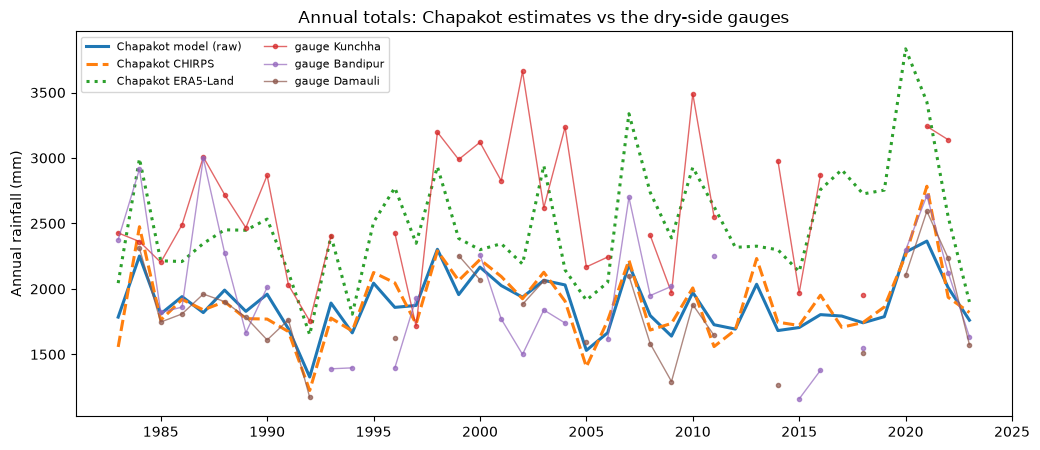

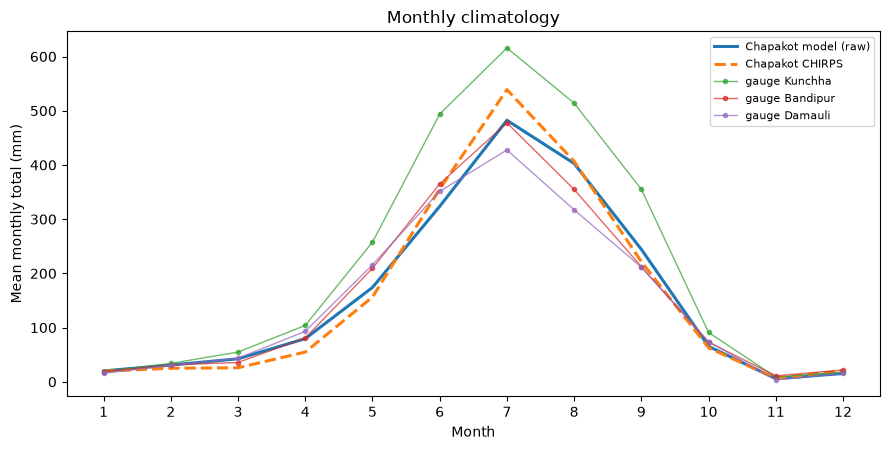

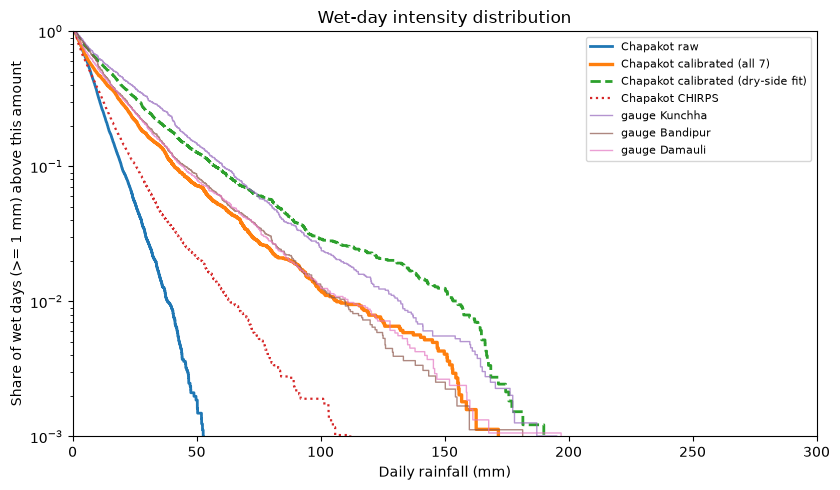

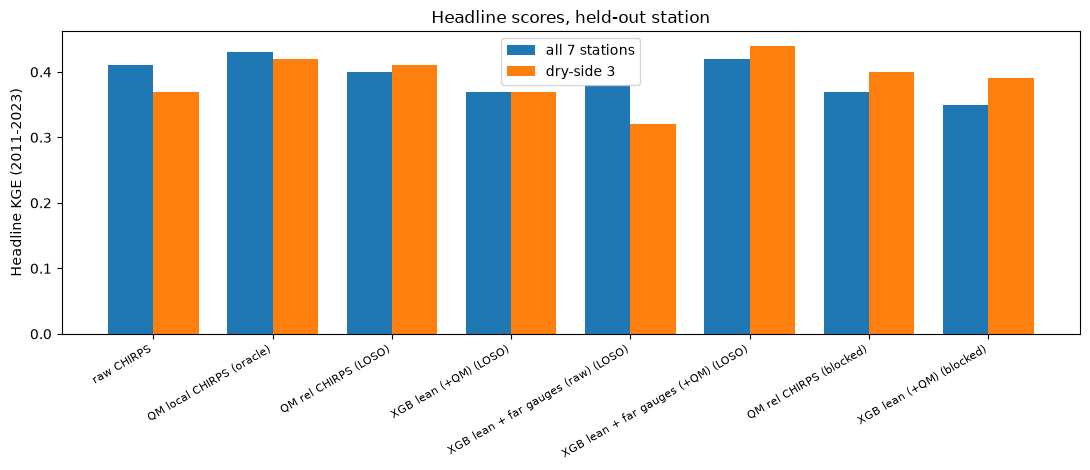

Headline summary (means over stations):
                                  KGE all 7  KGE dry-side 3  daily r  monthly r  mean |bias| %  false alarm  P95 hit rate
label                                                                                                                    
raw CHIRPS                             0.41            0.37     0.49       0.54           6.35         0.41          0.10
QM local CHIRPS (oracle)               0.43            0.42     0.44       0.51           6.81         0.31          0.23
QM rel CHIRPS/loso                     0.40            0.41     0.44       0.49          11.77         0.31          0.21
XGB lean (+QM)/loso                    0.37            0.37     0.42       0.54           9.98         0.29          0.23
XGB lean + far gauges (raw)/loso       0.38            0.32     0.57       0.68           8.32         0.42          0.02
XGB lean + far gauges (+QM)/loso       0.42            0.44     0.47       0.65          10.35         0.2

In [13]:
# ============================================================
# CELL 13 (05_xgboost_model): Figures and summary table for the write-up (reads from disk)
# What it does:
#   1) loads outputs/chapakot_reconstruction.parquet, data/processed/rain_final.parquet and
#      outputs/headline_scores.csv
#   2) Figure 1: annual totals 1983-2023 of the Chapakot model (raw, all 7), CHIRPS and ERA5-Land
#      next to the Kunchha, Bandipur and Damauli gauges (years with >= 350 valid days)
#   3) Figure 2: mean monthly totals of the same series (gauge months need >= 25 valid days)
#   4) Figure 3: wet-day exceedance curves (days >= 1 mm, log scale): Chapakot raw, calibrated
#      (all 7), calibrated (dry-side fit), CHIRPS, and the three dry gauges
#   5) Figure 4: headline KGE bars (all 7 stations and the dry-side 3) for the main methods
#   6) saves the figures in outputs/figures/ and outputs/summary_headline.csv; prints the table
# ============================================================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)

ROOT = Path.cwd().parent
PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)

chap = pd.read_parquet(OUT / "chapakot_reconstruction.parquet").set_index("date")
rain = pd.read_parquet(PROC / "rain_final.parquet")
DRY = ["Kunchha", "Bandipur", "Damauli"]

def annual(s, min_days=350):
    g = s.groupby(s.index.year)
    return g.sum(min_count=1).where(g.count() >= min_days)

def monthly_clim(s, min_valid=25):
    g = s.groupby([s.index.year, s.index.month])
    tot = (g.mean() * g.size()).where(g.count() >= min_valid)
    return tot.groupby(level=1).mean()

def exceed(s):
    v = np.sort(s.dropna().to_numpy())
    v = v[v >= 1.0]
    return v, 1 - np.arange(1, len(v) + 1) / (len(v) + 1)

# --- Figure 1: annual totals ---
fig, ax = plt.subplots(figsize=(10.5, 4.6))
for lab, s, ls in (("Chapakot model (raw)", chap["raw_all7"], "-"),
                   ("Chapakot CHIRPS", chap["chirps_blend_c"], "--"),
                   ("Chapakot ERA5-Land", chap["era_p_blend"], ":")):
    a = annual(s)
    ax.plot(a.index, a.values, ls, lw=2.2, label=lab)
for st in DRY:
    a = annual(rain[st])
    ax.plot(a.index, a.values, marker="o", ms=3, lw=1, alpha=0.7, label=f"gauge {st}")
ax.set_ylabel("Annual rainfall (mm)")
ax.set_title("Annual totals: Chapakot estimates vs the dry-side gauges")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
fig.savefig(FIG / "fig1_annual_totals.png", dpi=150)
plt.show()

# --- Figure 2: monthly climatology ---
fig, ax = plt.subplots(figsize=(9, 4.6))
for lab, s, ls in (("Chapakot model (raw)", chap["raw_all7"], "-"),
                   ("Chapakot CHIRPS", chap["chirps_blend_c"], "--")):
    m = monthly_clim(s)
    ax.plot(m.index, m.values, ls, lw=2.2, label=lab)
for st in DRY:
    m = monthly_clim(rain[st])
    ax.plot(m.index, m.values, marker="o", ms=3, lw=1, alpha=0.7, label=f"gauge {st}")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Mean monthly total (mm)")
ax.set_title("Monthly climatology")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "fig2_monthly_climatology.png", dpi=150)
plt.show()

# --- Figure 3: exceedance curves ---
fig, ax = plt.subplots(figsize=(8.5, 5))
for lab, s, kw in (("Chapakot raw", chap["raw_all7"], dict(lw=2)),
                   ("Chapakot calibrated (all 7)", chap["cal_all7"], dict(lw=2.4)),
                   ("Chapakot calibrated (dry-side fit)", chap["cal_dryonly"], dict(lw=2, ls="--")),
                   ("Chapakot CHIRPS", chap["chirps_blend_c"], dict(lw=1.6, ls=":"))):
    x, p = exceed(s)
    ax.step(x, p, where="post", label=lab, **kw)
for st in DRY:
    x, p = exceed(rain[st])
    ax.step(x, p, where="post", lw=1, alpha=0.7, label=f"gauge {st}")
ax.set_yscale("log")
ax.set_xlim(0, 300)
ax.set_ylim(1e-3, 1)
ax.set_xlabel("Daily rainfall (mm)")
ax.set_ylabel("Share of wet days (>= 1 mm) above this amount")
ax.set_title("Wet-day intensity distribution")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "fig3_exceedance.png", dpi=150)
plt.show()

# --- Figure 4 and summary table: headline scores ---
hs = pd.read_csv(OUT / "headline_scores.csv")
dry_rows = hs["station"].isin(DRY)
labels = ["raw CHIRPS", "QM local CHIRPS (oracle)", "QM rel CHIRPS/loso", "XGB lean (+QM)/loso",
          "XGB lean + far gauges (raw)/loso", "XGB lean + far gauges (+QM)/loso",
          "QM rel CHIRPS/bloc", "XGB lean (+QM)/bloc"]
tab = pd.DataFrame({
    "KGE all 7": hs.groupby("label")["kge"].mean(),
    "KGE dry-side 3": hs[dry_rows].groupby("label")["kge"].mean(),
    "daily r": hs.groupby("label")["r"].mean(),
    "monthly r": hs.groupby("label")["r_mon"].mean(),
    "mean |bias| %": hs.assign(a=hs["pbias"].abs()).groupby("label")["a"].mean(),
    "false alarm": hs.groupby("label")["wet_far"].mean(),
    "P95 hit rate": hs.groupby("label")["p95_pod"].mean(),
}).loc[labels].round(2)
tab.to_csv(OUT / "summary_headline.csv")

fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(labels))
w = 0.38
ax.bar(x - w / 2, tab["KGE all 7"], w, label="all 7 stations")
ax.bar(x + w / 2, tab["KGE dry-side 3"], w, label="dry-side 3")
ax.set_xticks(x)
ax.set_xticklabels([l.replace("/loso", " (LOSO)").replace("/bloc", " (blocked)") for l in labels],
                   rotation=30, ha="right", fontsize=8)
ax.set_ylabel("Headline KGE (2011-2023)")
ax.set_title("Headline scores, held-out station")
ax.legend()
plt.tight_layout()
fig.savefig(FIG / "fig4_headline_kge.png", dpi=150)
plt.show()

print("Headline summary (means over stations):")
print(tab.to_string())
print("\nSaved: outputs/figures/fig1..fig4 and outputs/summary_headline.csv")